vol-managed spy + low-beta sector pair. data via yfinance, runs top to bottom in colab (~1–2 min).

one 15% risk budget shared by two sleeves:

- sleeve 2 (spread): each year-end take the 2 lowest-beta sector etfs vs spy (past 1y). `z = (log(a/b) - mean_60) / std_60`. |z| > 2 → long cheap, short rich, legs sized beta-neutral from the same prior-year betas (2x gross). exit at |z| < 0.5.
- sleeve 1 (equity): gets what is left of the budget after the spread's realized vol (63d): hold `sqrt(TARGET_VOL² − vol_pair²) / vol_spy_21d` in spy, cap 2x, reset at month-end. rest in t-bills, borrow at t-bill + 50bp above 1x.

In [1]:
%pip install -q yfinance statsmodels
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, yfinance as yf
pd.set_option('display.width', 200)
print('yfinance', yf.__version__, '| pandas', pd.__version__)

/tmp/claude-0/-home-user-FinancialModellingGroupN/0d685fe3-a9d9-53c6-8ec7-41b7553e8539/scratchpad/colabenv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


yfinance 1.8.0 | pandas 2.2.2


### params

In [2]:
START, END = '2006-01-01', '2025-12-31'   # evaluation window: first and last return day (inclusive)
DATA_START = '1999-01-01'                 # sector ETFs start Dec-1998; earlier years serve as warm-up / formation data
IS_END = '2015-12-31'                     # split for the in-sample / out-of-sample check

# Sleeve 1: volatility-managed SPY
TARGET_VOL = 0.15     # annualised volatility target
VOL_DAYS   = 21       # look-back for realised volatility (~1 month)
MAX_LEV    = 2.0      # cap on SPY exposure
PAIR_VOL_DAYS = 63    # look-back for the spread sleeve's realised volatility (~3 months), taken out of the budget first

# Sleeve 2: pair overlay
SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']   # the 9 original Select Sector SPDRs
BETA_YEARS = 1        # look-back (calendar years) for the beta estimate used to pick the pair
Z_WIN, Z_IN, Z_OUT = 60, 2.0, 0.5
PAIR_SIZE = 1.0       # notional per leg as a fraction of equity

# Implementation costs
COST       = 0.0010   # 10 bp of notional traded (spread + commission + slippage)
FIN_SPREAD = 0.0050   # borrowing cost above the T-bill rate, p.a.
SHORT_FEE  = 0.0025   # stock-borrow fee on short notional, p.a.

ASSETS  = ['SPY'] + SECTORS
TICKERS = ASSETS + ['^SP500TR', '^IRX']

### data
- yfinance, `auto_adjust=True` → split + dividend adjusted, i.e. total returns
- universe: spy + 9 original sector spdrs, all live since dec-1998, fixed upfront → no survivorship
- benchmark: `^SP500TR`
- rf: `^IRX / 100 / 252`, lagged 1 day
- signals daily, stats on monthly returns

In [3]:
raw = yf.download(TICKERS, start=DATA_START, end=pd.Timestamp(END) + pd.Timedelta(days=1),
                  auto_adjust=True, progress=False)['Close'][TICKERS]

# The four checks from Lecture 3: shape, date range, missing values, plot
print('shape:', raw.shape)
print('date range:', raw.index.min().date(), '->', raw.index.max().date())
print('missing values per column:\n', raw.isna().sum().to_string())

shape: (6791, 12)
date range: 1999-01-04 -> 2025-12-31
missing values per column:
 Ticker
SPY         0
XLB         0
XLE         0
XLF         0
XLI         0
XLK         0
XLP         0
XLU         0
XLV         0
XLY         0
^SP500TR    0
^IRX        8


dropna removed 0 of 6791 rows; sample now 1999-01-04 -> 2025-12-31


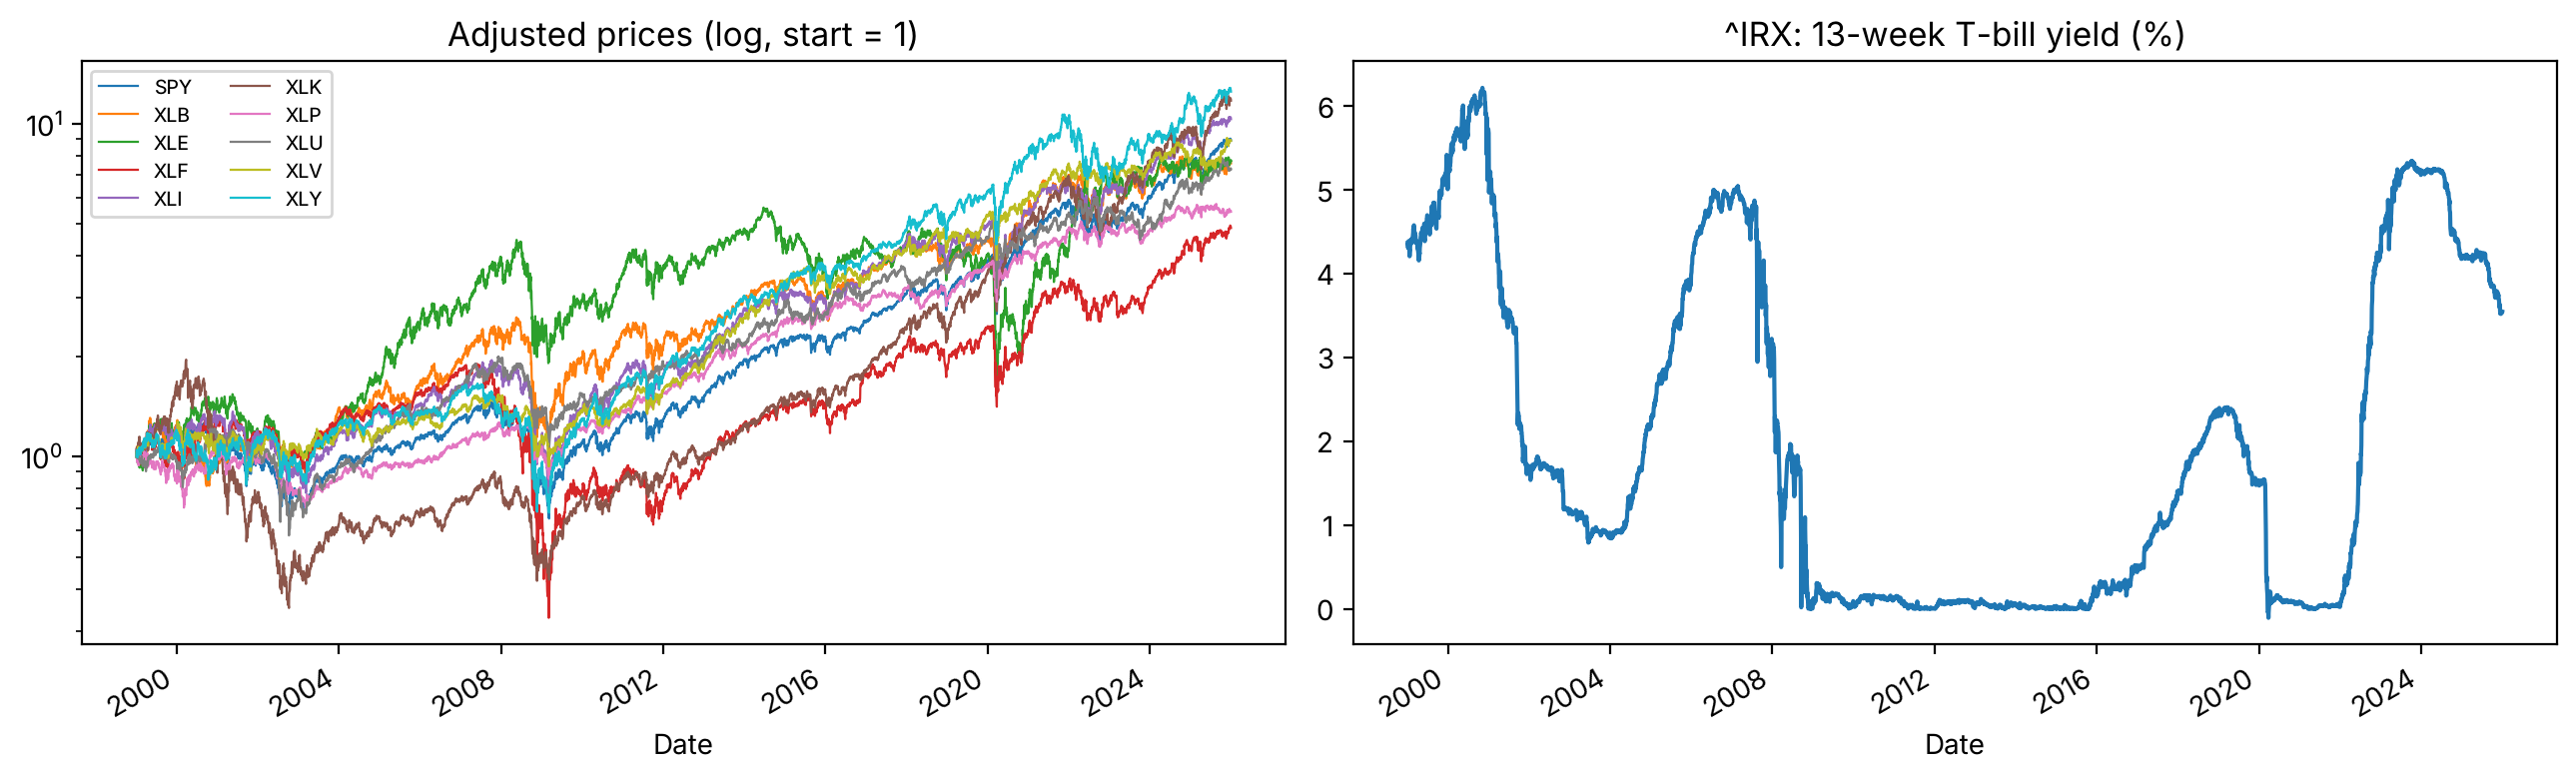

In [4]:
assert raw[ASSETS + ['^SP500TR']].notna().all().all(), 'download incomplete (rate limit?): re-run this cell'
px = raw.copy()
px['^IRX'] = px['^IRX'].ffill()           # T-bill quote occasionally missing on a trading day: carry last yield
n0 = len(px)
px = px.dropna()
print(f'dropna removed {n0 - len(px)} of {n0} rows; sample now {px.index.min().date()} -> {px.index.max().date()}')
assert px.index.min() < pd.Timestamp(START) and px.index.max() == pd.Timestamp(END), 'sample does not cover START..END'

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(px[ASSETS] / px[ASSETS].iloc[0]).plot(ax=ax[0], logy=True, lw=.8, title='Adjusted prices (log, start = 1)')
ax[0].legend(ncol=2, fontsize=7)
px['^IRX'].plot(ax=ax[1], title='^IRX: 13-week T-bill yield (%)')
plt.tight_layout(); plt.show()

In [5]:
ret = px[ASSETS + ['^SP500TR']].pct_change()
rf_d = (px['^IRX'] / 100 / 252).shift(1)     # yield known at t-1 is earned on day t

# Sanity check: SPY (adjusted) vs the S&P 500 total-return index should differ only by SPY's ~0.09% fee
yr = (1 + ret.loc[START:END, ['SPY', '^SP500TR']]).groupby(lambda d: d.year).prod() - 1
print('mean annual return SPY vs ^SP500TR:', yr.mean().round(4).to_dict(),
      '| correlation of daily returns:', round(ret.loc[START:END, 'SPY'].corr(ret.loc[START:END, '^SP500TR']), 4))

mean annual return SPY vs ^SP500TR: {'SPY': 0.1243, '^SP500TR': 0.1252} | correlation of daily returns: 0.9938


### signals
only closes ≤ t. trade at close t, earn from t+1. pair for year y picked at the last close of y−1. a new pair starts flat, so opening it needs |z| > 2.

In [6]:
from itertools import groupby

def month_end_flag(idx):
    return ~idx.to_period('M').duplicated(keep='last')                 # last trading day of each month

def spy_exposure(px, pair_ret=None):
    # one risk budget: the spread sleeve's realised vol is taken out first, the equity sleeve gets the rest
    vol = px['SPY'].pct_change().rolling(VOL_DAYS).std() * np.sqrt(252)   # trailing window ending at t
    budget = TARGET_VOL if pair_ret is None else \
             np.sqrt((TARGET_VOL ** 2 - (pair_ret.rolling(PAIR_VOL_DAYS).std() * np.sqrt(252)) ** 2).clip(lower=0))
    return (budget / vol).clip(upper=MAX_LEV)

def pair_returns(px, P):
    return (P.shift(1) * px[SECTORS].pct_change()).sum(axis=1)        # positions set at t-1 earn day t

def sector_betas(px, lo, hi):
    r = px[ASSETS].pct_change().loc[lo:hi]
    return r.cov()['SPY'][SECTORS] / r['SPY'].var()                    # beta = cov / var (lecture 3)

def lowbeta_pick(px, year, years=BETA_YEARS):
    # the two lowest-beta sectors over the `years` calendar years before `year`
    return tuple(sorted(sector_betas(px, str(year - years), str(year - 1)).nsmallest(2).index))

def zscore(px, a, b, win=Z_WIN):
    s = np.log(px[a] / px[b])
    return (s - s.rolling(win).mean()) / s.rolling(win).std()           # trailing window ending at t

def positions(z, z_in=Z_IN, z_out=Z_OUT):
    pos, p = [], 0
    for zt in z:
        if np.isnan(zt):                 p = 0
        elif p == 0 and zt >  z_in:      p = -1   # a rich vs b: short a, long b
        elif p == 0 and zt < -z_in:      p = +1   # a cheap vs b: long a, short b
        elif p != 0 and abs(zt) < z_out: p = 0    # spread has reverted: close
        pos.append(p)
    return np.array(pos, dtype=float)

def pair_targets(px, pick=lowbeta_pick, win=Z_WIN, z_in=Z_IN, z_out=Z_OUT, beta_neutral=True):
    # target sector weights per day (+1 = 100% long, -1 = 100% short) and the pair chosen for each year
    hold_year = px.index.year + (month_end_flag(px.index) & (px.index.month == 12))   # last close of december: next year's pair
    tgt = pd.DataFrame(0.0, index=px.index, columns=SECTORS)
    z_active = pd.Series(np.nan, index=px.index)
    chosen = {y: pick(px, y) for y in range(int(START[:4]), hold_year.max() + 1)}
    for (a, b), ys in groupby(chosen, key=chosen.get):
        ys = list(ys)                  # consecutive years with the same pair = one block
        m = np.isin(hold_year, ys)
        z = zscore(px, a, b, win).where(m)                              # nan outside the block, so a new pair starts flat
        pos = positions(z, z_in, z_out)
        for y in ys:                                                    # hedge ratio from the prior year's betas
            my = hold_year == y
            be = sector_betas(px, str(y - 1), str(y - 1))
            wa, wb = (2 * be[b] / (be[a] + be[b]), 2 * be[a] / (be[a] + be[b])) if beta_neutral else (1.0, 1.0)
            tgt.loc[my, a] += pos[my] * wa; tgt.loc[my, b] -= pos[my] * wb   # wa*beta_a = wb*beta_b, wa + wb = 2
        z_active[m] = z[m]
    return tgt, chosen, z_active

tgt_pair, chosen, z_active = pair_targets(px)
expo = spy_exposure(px, pair_returns(px, tgt_pair * PAIR_SIZE))

betas = pd.DataFrame({y: sector_betas(px, str(y - BETA_YEARS), str(y - 1)) for y in chosen}).T.round(2)
betas['pair held'] = [f'{a}/{b}' for a, b in chosen.values()]
print('Pair held each year (chosen from the prior year\'s betas):')
print(betas.loc[:int(END[:4]), 'pair held'].value_counts().to_string())
print(f"({int(END[:4]) + 1} row: pair picked at the last close of the sample, not traded in the backtest)")
betas

Pair held each year (chosen from the prior year's betas):
pair held
XLP/XLU    14
XLP/XLV     6
(2026 row: pair picked at the last close of the sample, not traded in the backtest)


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,pair held
2006,1.21,1.37,0.98,0.99,0.94,0.71,0.97,0.73,1.08,XLP/XLV
2007,1.36,1.27,1.00,0.99,1.19,0.61,0.62,0.71,0.99,XLP/XLU
2008,1.24,1.24,1.35,0.91,0.89,0.54,0.78,0.66,0.98,XLP/XLV
2009,0.97,1.24,1.45,0.85,0.93,0.48,0.75,0.60,0.91,XLP/XLV
2010,1.13,1.18,2.15,1.14,0.88,0.50,0.54,0.54,1.09,XLP/XLV
2011,1.26,1.21,1.31,1.18,0.98,0.59,0.70,0.72,1.08,XLP/XLU
2012,1.28,1.27,1.36,1.16,0.94,0.58,0.61,0.81,1.00,XLP/XLU
2013,1.22,1.25,1.24,1.11,1.06,0.58,0.37,0.74,0.99,XLP/XLU
2014,1.12,1.08,1.21,1.07,0.88,0.82,0.73,0.94,1.05,XLP/XLU
2015,1.08,1.12,1.04,1.12,1.03,0.66,0.50,1.09,1.05,XLP/XLU


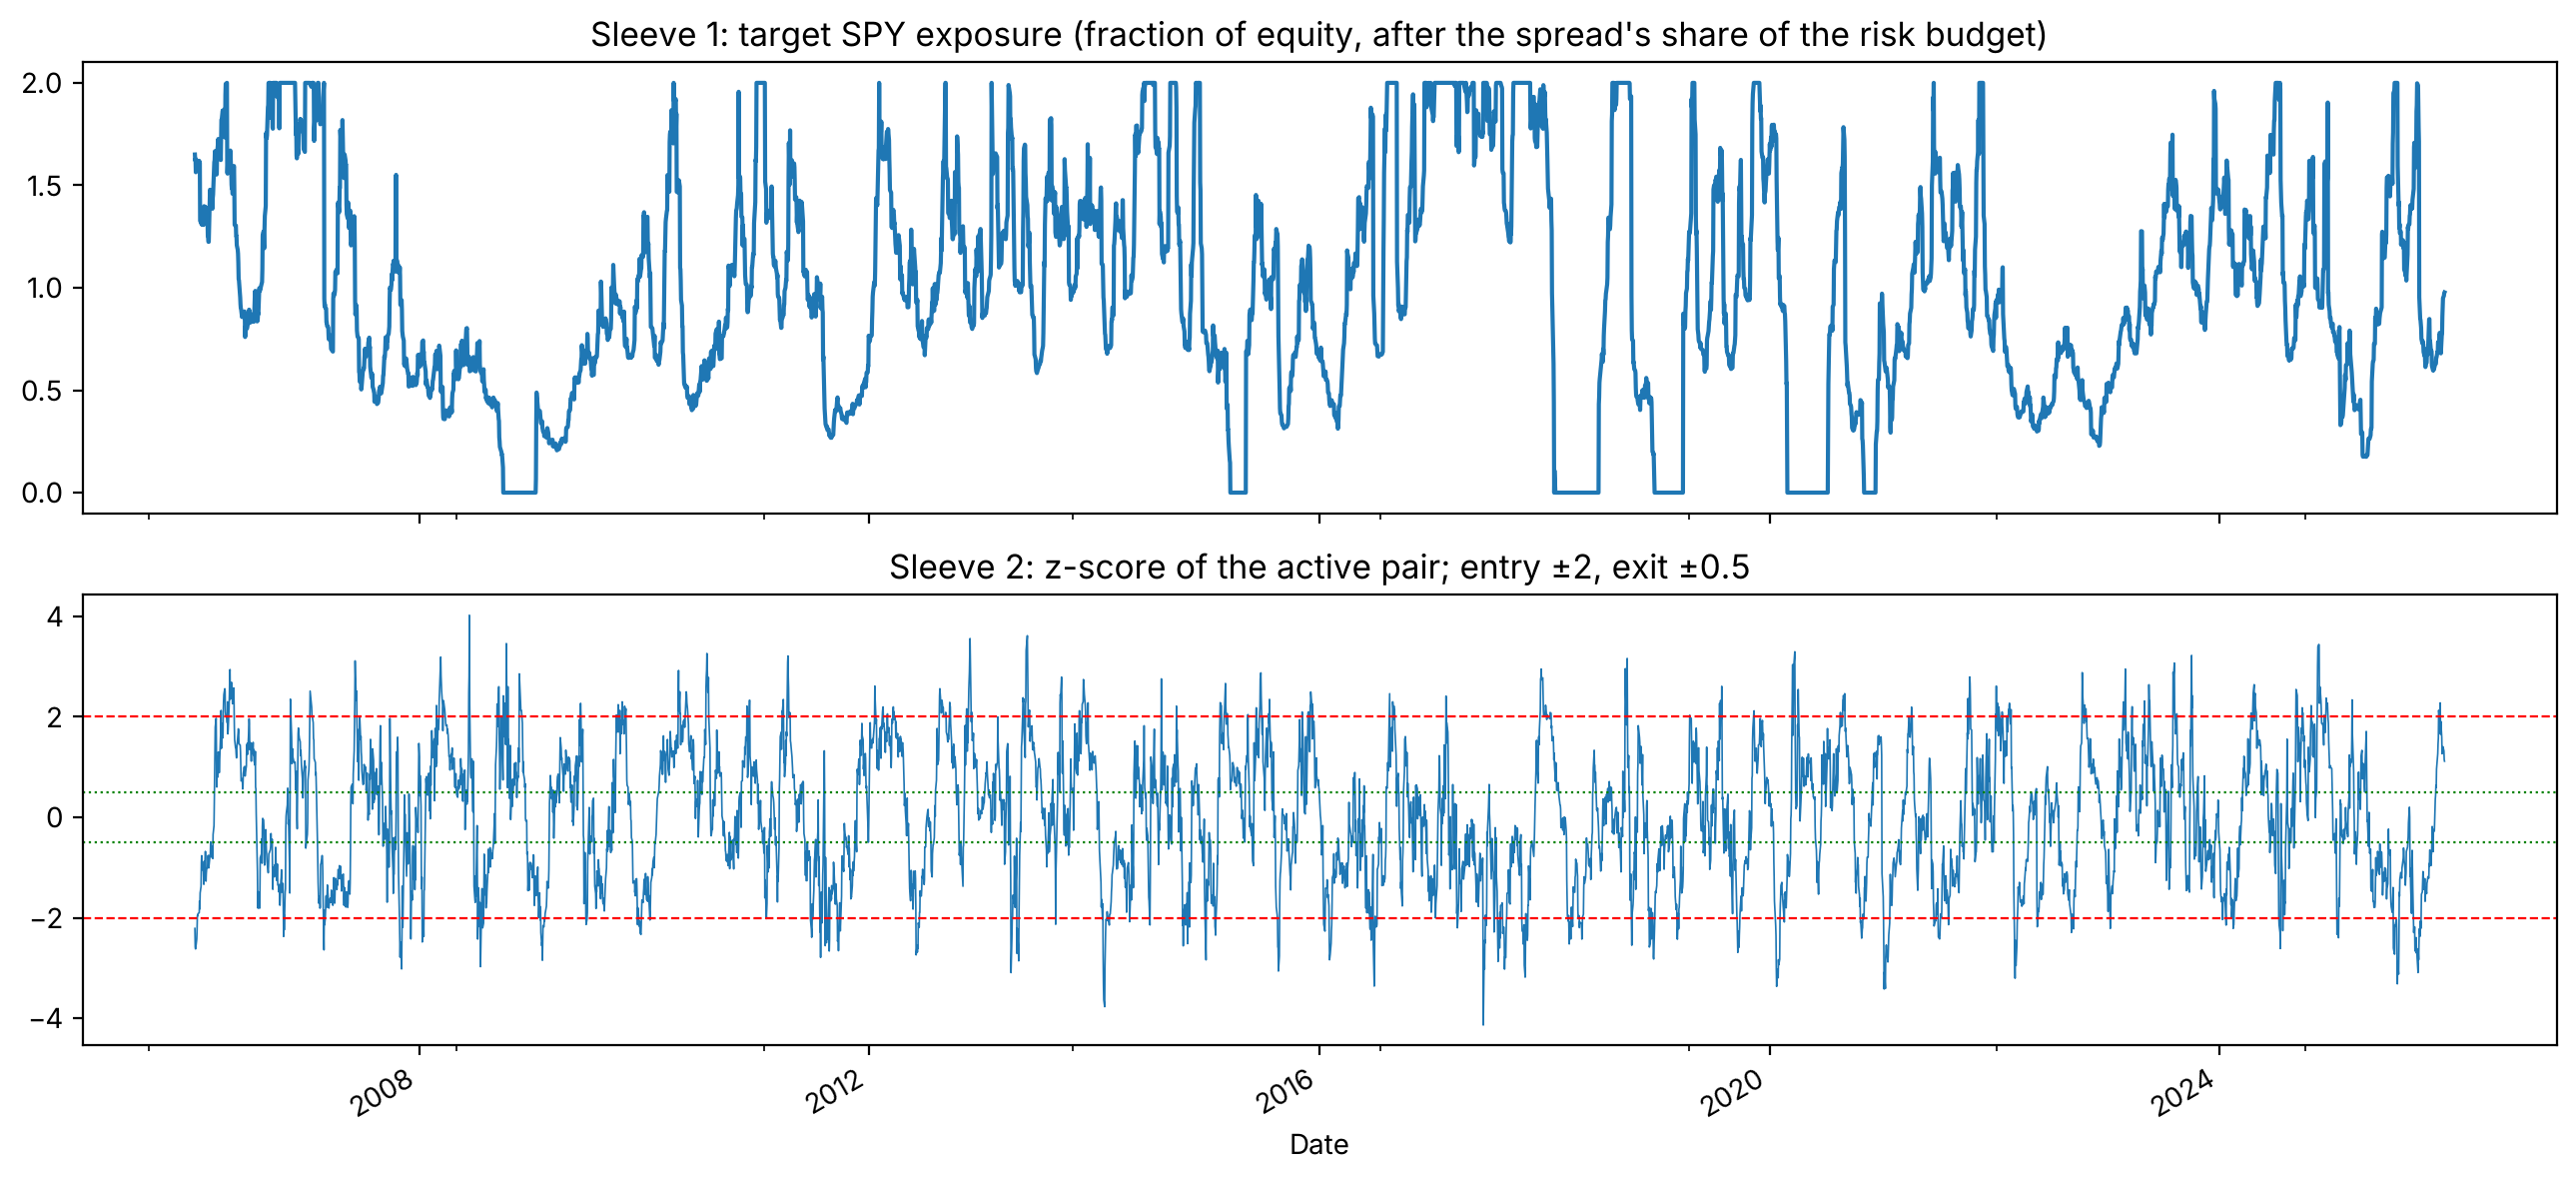

pair position open on 42% of days


In [7]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
expo.loc[START:END].plot(ax=ax[0], title='Sleeve 1: target SPY exposure (fraction of equity, after the spread\'s share of the risk budget)')
z_active.loc[START:END].plot(ax=ax[1], lw=.6, title='Sleeve 2: z-score of the active pair; entry ±2, exit ±0.5')
for h in [Z_IN, -Z_IN]: ax[1].axhline(h, c='r', ls='--', lw=.8)
for h in [Z_OUT, -Z_OUT]: ax[1].axhline(h, c='g', ls=':', lw=.8)
plt.tight_layout(); plt.show()
open_ = tgt_pair.abs().sum(axis=1).loc[START:END] > 0
print(f'pair position open on {open_.mean():.0%} of days')

### backtest
- weights from close t−1 earn day t. cash earns rf, borrowed cash pays rf + 50bp, shorts pay 25bp p.a.
- positions drift with prices, no implicit daily rebalance
- trades only at month-end (spy) or when the pair target changes
- cost = `COST × |target − drifted|`
- `lag=2` → trade one day later

In [8]:
def backtest(px, use_spy=True, pair_size=PAIR_SIZE, cost=COST, lag=1, pair_kw={}, vol_budget=True):
    P = pair_targets(px, **pair_kw)[0] * pair_size
    e = spy_exposure(px, pair_returns(px, P) if vol_budget else None) if use_spy else 0 * px['SPY']
    me = pd.Series(month_end_flag(px.index), index=px.index)
    e, P, me = e.shift(lag - 1), P.shift(lag - 1).fillna(0), me.shift(lag - 1, fill_value=False)   # lag=2: trade a day late

    idx = px.loc[:END].index[px.index.searchsorted(pd.Timestamp(START)) - 1:]   # from the last close before START
    R, rf = px[ASSETS].pct_change().loc[idx].values, rf_d.loc[idx].values
    e, P, me = e.loc[idx].values, P.loc[idx].values, me.loc[idx].values

    w, rows = np.zeros(len(ASSETS)), []                               # weights: spy + 9 sectors, rest is cash
    for i in range(len(idx)):
        cash = 1 - w.sum()
        gross = w @ R[i] + cash * (rf[i] + (FIN_SPREAD / 252 if cash < 0 else 0)) \
                - np.abs(np.minimum(w, 0)).sum() * SHORT_FEE / 252
        drift = w * (1 + R[i]) / (1 + gross)                          # positions drift with prices
        tgt = drift.copy()
        if i == 0 or me[i]: tgt[0] = e[i]                             # spy: reset at month-end
        if i == 0 or (P[i] != P[i - 1]).any(): tgt[1:] = P[i]         # pair: trade only when the target changes
        turn = np.abs(tgt - drift).sum()
        rows.append((gross, gross - turn * cost, turn, tgt[0], np.abs(tgt).sum()))
        w = tgt
    out = pd.DataFrame(rows, index=idx, columns=['gross', 'net', 'turnover', 'w_spy', 'gross_exposure'])
    return out.iloc[1:]                                               # returns start the day after START's close

bt = backtest(px)
print(bt.describe().T[['mean', 'min', 'max']])

                    mean       min       max
gross           0.000815 -0.075728  0.133384
net             0.000713 -0.075728  0.133384
turnover        0.102254  0.000000  2.614350
w_spy           0.995494  0.000000  2.167182
gross_exposure  1.853882  0.000000  4.316536


### look-ahead check
drop all data after a cutoff, assert signals, pairs and returns before it are unchanged.

In [9]:
for cut in ['2010-06-30', '2015-12-31', '2020-03-31']:
    px_cut = px.loc[:cut]
    P_full, P_cut = pair_targets(px)[0], pair_targets(px_cut)[0]
    assert np.allclose(P_full.loc[:cut], P_cut)
    assert np.allclose(spy_exposure(px, pair_returns(px, P_full)).loc[:cut].dropna(), spy_exposure(px_cut, pair_returns(px_cut, P_cut)).dropna())
    full, trunc = backtest(px).loc[:cut], backtest(px_cut)
    assert np.allclose(full.values, trunc.values), cut
    print(f'cut-off {cut}: signals, pair choices and {len(trunc)} daily returns identical with and without future data ✓')

cut-off 2010-06-30: signals, pair choices and 1131 daily returns identical with and without future data ✓


cut-off 2015-12-31: signals, pair choices and 2517 daily returns identical with and without future data ✓


cut-off 2020-03-31: signals, pair choices and 3585 daily returns identical with and without future data ✓


dividend adjustment scales all prices before a dividend by one factor → constant shift in `log(a/b)` within the window → cancels in the z-score. returns unaffected.

### performance

In [10]:
monthly = lambda r: (1 + r).resample('ME').prod() - 1
bench_d = ret['^SP500TR'].loc[bt.index]
rf_m = monthly(rf_d.loc[bt.index])
bench_m = monthly(bench_d)

def stats(r_m):
    # Monthly-return statistics. Means x12, volatilities x sqrt(12); beta not annualised.
    rf, b = rf_m.loc[r_m.index], bench_m.loc[r_m.index]
    ex, bex = r_m - rf, b - rf
    ols = sm.OLS(ex, sm.add_constant(bex)).fit()
    a, beta = ols.params.iloc[0], ols.params.iloc[1]
    wealth = (1 + r_m).cumprod()
    return pd.Series({
        'Ann. avg return': r_m.mean() * 12,
        'Ann. volatility': r_m.std() * np.sqrt(12),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(12),
        'Alpha (ann.)': a * 12,
        'Alpha t-stat': ols.tvalues.iloc[0],
        'Beta': beta,
        'Information ratio': a / ols.resid.std() * np.sqrt(12),
        'Max drawdown (monthly)': (wealth / wealth.cummax() - 1).min(),
    })

strat_m = monthly(bt.net)
table = pd.DataFrame({'Strategy (net)': stats(strat_m), 'Strategy (gross)': stats(monthly(bt.gross)),
                      'S&P 500 TR': stats(bench_m)})
table.loc[['Alpha t-stat', 'Information ratio'], 'S&P 500 TR'] = np.nan   # benchmark regressed on itself: undefined
print(f'{len(strat_m)} monthly observations, {strat_m.index[0]:%Y-%m} to {strat_m.index[-1]:%Y-%m}')
table.round(4)

240 monthly observations, 2006-01 to 2025-12


,Strategy (net),Strategy (gross),S&P 500 TR
Ann. avg return,0.1736,0.1996,0.1163
Ann. volatility,0.1434,0.1442,0.1509
Sharpe ratio,1.0973,1.2723,0.6630
Alpha (ann.),0.0966,0.1233,-0.0000
Alpha t-stat,3.8381,4.8228,NaN
Beta,0.6074,0.6014,1.0000
Information ratio,0.8757,1.1004,NaN
Max drawdown (monthly),-0.1476,-0.1359,-0.5095


- monthly returns compounded from daily, 2006-01 → 2025-12
- ann. return = mean × 12, vol = std × √12
- sharpe = mean(r − rf) / std(r − rf) × √12
- ols: `r − rf = α + β (r_bench − rf) + ε`. α × 12, β not annualised
- ir = α / σ(ε) × √12
- net = after 10bp per unit traded, financing, borrow fee. no taxes

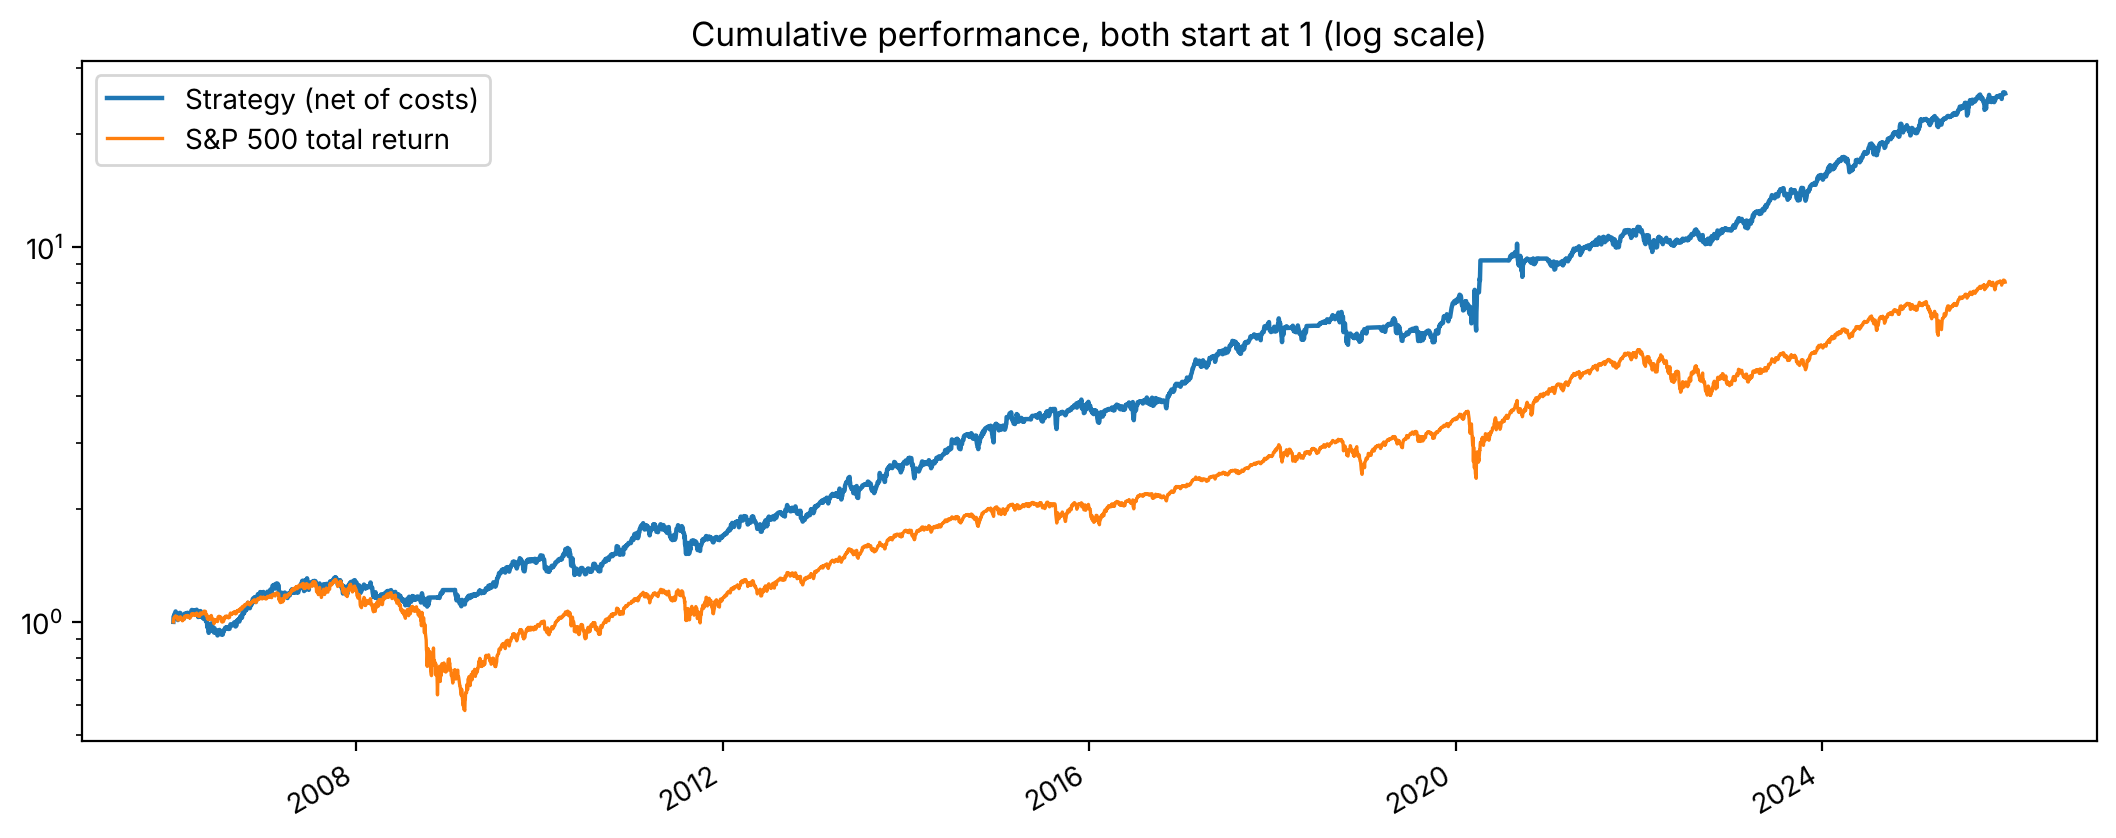

$1 grew to: strategy 25.70, S&P 500 TR 8.06


In [11]:
def wealth(r):
    w = (1 + r).cumprod()
    return pd.concat([pd.Series(1.0, index=[w.index[0] - pd.Timedelta(days=1)]), w])

fig, ax = plt.subplots(figsize=(13, 5))
wealth(bt.net).plot(ax=ax, label='Strategy (net of costs)', lw=1.6)
wealth(bench_d).plot(ax=ax, label='S&P 500 total return', lw=1.2)
ax.set_yscale('log'); ax.set_title('Cumulative performance, both start at 1 (log scale)'); ax.legend(); plt.show()
print(f'$1 grew to: strategy {wealth(bt.net).iloc[-1]:.2f}, S&P 500 TR {wealth(bench_d).iloc[-1]:.2f}')

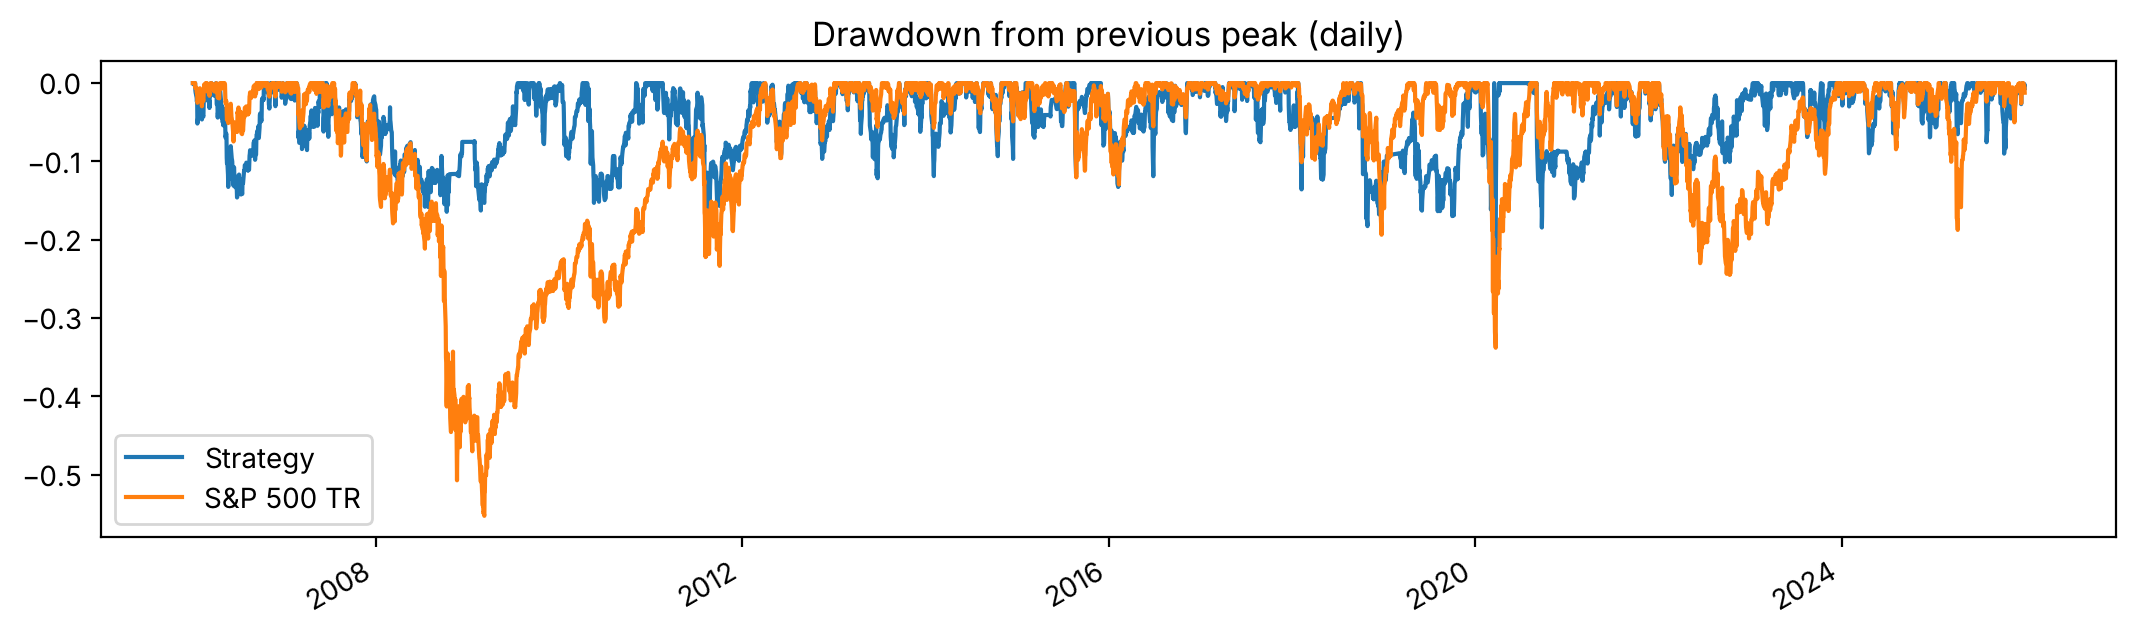

daily max drawdown: strategy -22.1%, benchmark -55.3%


In [12]:
dd = lambda r: wealth(r) / wealth(r).cummax() - 1
fig, ax = plt.subplots(figsize=(13, 3.5))
dd(bt.net).plot(ax=ax, label='Strategy'); dd(bench_d).plot(ax=ax, label='S&P 500 TR')
ax.set_title('Drawdown from previous peak (daily)'); ax.legend(); plt.show()
print('daily max drawdown: strategy {:.1%}, benchmark {:.1%}'.format(dd(bt.net).min(), dd(bench_d).min()))

### attribution

In [13]:
spy_only  = backtest(px, use_spy=True,  pair_size=0)      # sleeve 1 alone, pair switched off
pair_only = backtest(px, use_spy=False, pair_size=1.0)    # sleeve 2 alone, capital otherwise in T-bills
sleeves = {'Vol-managed SPY only': spy_only.net, 'Pair only (+ T-bills)': pair_only.net, 'Combined strategy': bt.net}
attr = pd.DataFrame({k: stats(monthly(v)) for k, v in sleeves.items()})
attr.loc['Ann. excess return over T-bills'] = {k: (monthly(v) - rf_m).mean() * 12 for k, v in sleeves.items()}
attr.loc['$1 grows to'] = {k: wealth(v).iloc[-1] for k, v in sleeves.items()}
print('correlation of monthly returns, SPY sleeve vs pair sleeve:',
      round(monthly(spy_only.net).corr(monthly(pair_only.net)), 3))
attr.round(4)

correlation of monthly returns, SPY sleeve vs pair sleeve: -0.131


,Vol-managed SPY only,Pair only (+ T-bills),Combined strategy
Ann. avg return,0.1293,0.0745,0.1736
Ann. volatility,0.1455,0.0910,0.1434
Sharpe ratio,0.7773,0.6426,1.0973
Alpha (ann.),0.0290,0.0606,0.0966
Alpha t-stat,1.7831,2.9281,3.8381
Beta,0.8409,-0.0226,0.6074
Information ratio,0.4068,0.6681,0.8757
Max drawdown (monthly),-0.3278,-0.1954,-0.1476
Ann. excess return over T-bills,0.1131,0.0583,0.1574
$1 grows to,10.6107,4.0868,25.6979


Excess return: SPY sleeve 11.31% + pair 5.83% = 17.15% (combined actual 15.74%; the gap is compounding/interaction)
Share of excess return: SPY sleeve 66%, pair 34%
Alpha: SPY sleeve 2.90%, pair 6.06%, combined 9.66%


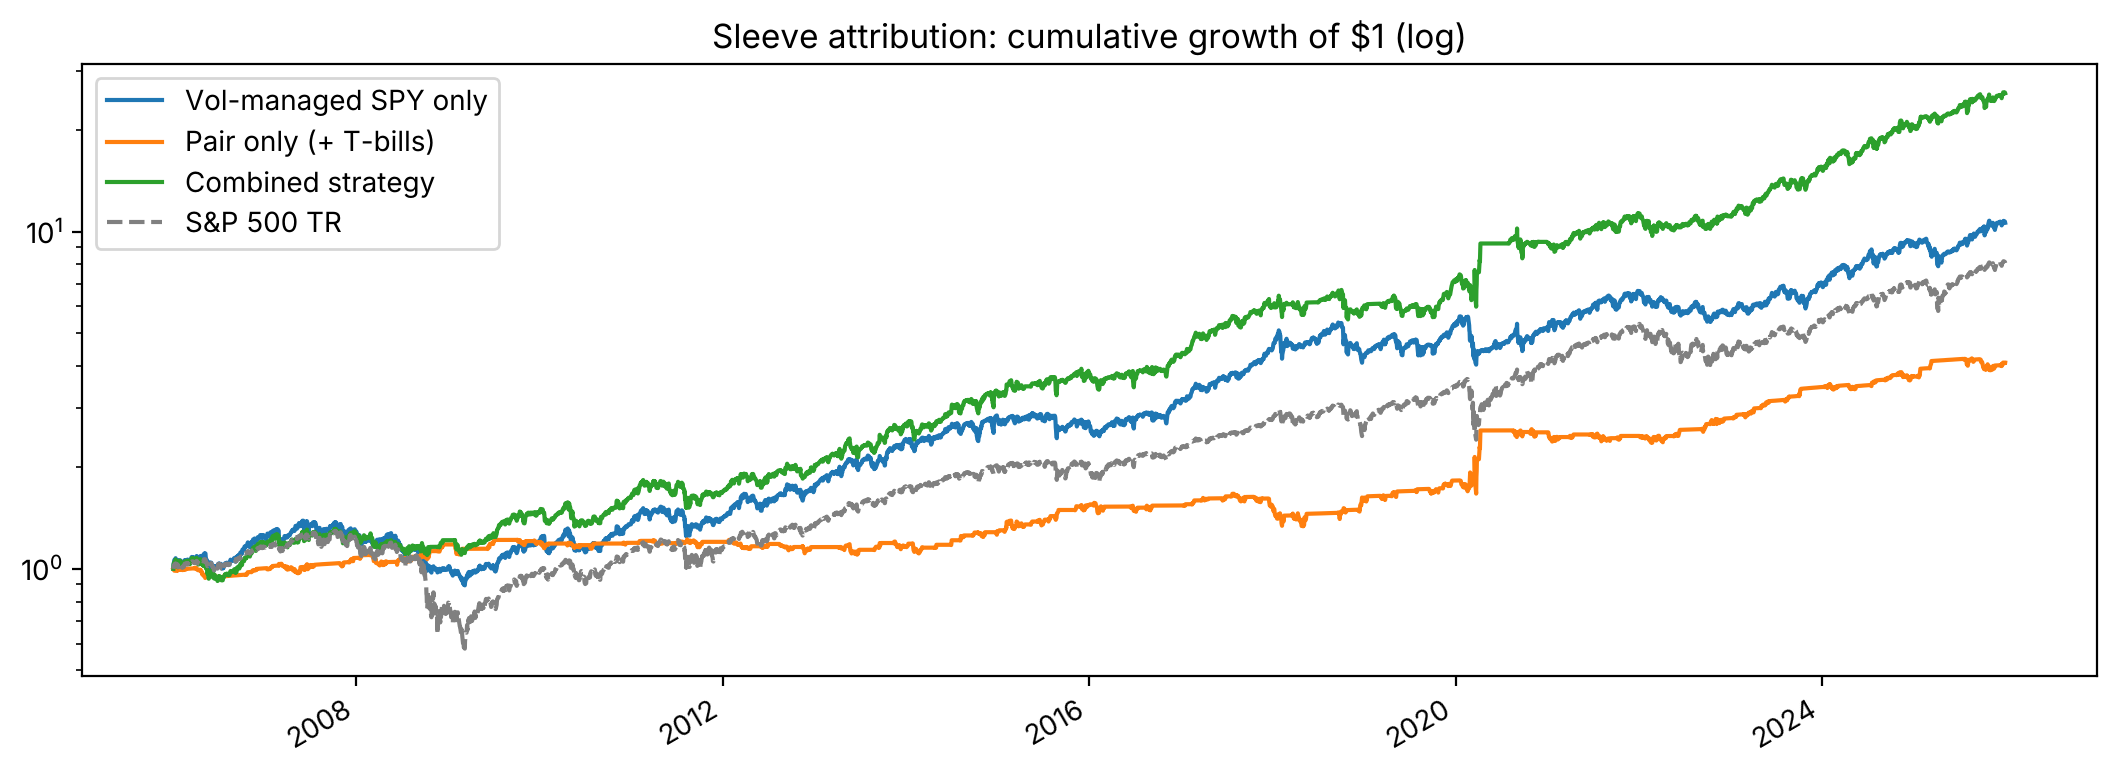

In [14]:
ex = attr.loc['Ann. excess return over T-bills']
share = ex.iloc[:2] / ex.iloc[:2].sum()
print(f"Excess return: SPY sleeve {ex.iloc[0]:.2%} + pair {ex.iloc[1]:.2%} = {ex.iloc[:2].sum():.2%} "
      f"(combined actual {ex.iloc[2]:.2%}; the gap is compounding/interaction)")
print(f"Share of excess return: SPY sleeve {share.iloc[0]:.0%}, pair {share.iloc[1]:.0%}")
al = attr.loc['Alpha (ann.)']
print(f"Alpha: SPY sleeve {al.iloc[0]:.2%}, pair {al.iloc[1]:.2%}, combined {al.iloc[2]:.2%}")
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, v in sleeves.items(): wealth(v).plot(ax=ax, label=k)
wealth(bench_d).plot(ax=ax, label='S&P 500 TR', ls='--', c='grey')
ax.set_yscale('log'); ax.set_title('Sleeve attribution: cumulative growth of $1 (log)'); ax.legend(); plt.show()

### risk profile
- monthly net returns. var and cvar are one-month losses (positive = loss)
- historical var: 5th percentile month. normal var: mean − z·σ. cornish-fisher: z adjusted for skew and kurtosis, shows fat tails at 99%
- cvar (expected shortfall): average loss in the worst 5% of months
- sortino = mean excess return / downside deviation (excess returns below 0) × √12. calmar = cagr / |max drawdown|
- up / down capture: our average return in months the s&p rose (fell), divided by the s&p's average in those months
- active ir = mean(r − r_s&p) / tracking error × √12. newey-west: alpha t-stat robust to autocorrelation and heteroskedasticity (6 lags)
- the confidence level can be changed: `var_es(r, level)` gives var and expected shortfall at any level (the app has it as a slider)

In [15]:
def risk_stats(r_m):
    rf, b = rf_m.loc[r_m.index], bench_m.loc[r_m.index]
    ex, act = r_m - rf, r_m - b
    w = (1 + r_m).cumprod()
    S, K = r_m.skew(), r_m.kurt()                                  # sample skewness, excess kurtosis
    cf = lambda z: z + (z**2 - 1) * S / 6 + (z**3 - 3 * z) * K / 24 - (2 * z**3 - 5 * z) * S**2 / 36   # Cornish-Fisher
    var = lambda z: -(r_m.mean() + z * r_m.std())                  # z = normal quantile: -1.645 (95%), -2.326 (99%)
    q = r_m.quantile(.05)
    up, dn = b > 0, b < 0
    hac = sm.OLS(ex, sm.add_constant(b - rf)).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
    return pd.Series({
        'Skewness': S,
        'Excess kurtosis': K,
        'VaR 95%, historical': -q,
        'VaR 95%, normal': var(-1.645),
        'VaR 99%, normal': var(-2.326),
        'VaR 99%, Cornish-Fisher': var(cf(-2.326)),
        'CVaR 95% (expected shortfall)': -r_m[r_m <= q].mean(),
        'Worst month': r_m.min(),
        'Positive months': (r_m > 0).mean(),
        'Sortino ratio': ex.mean() / np.sqrt((ex.clip(upper=0) ** 2).mean()) * np.sqrt(12),
        'Calmar ratio': (w.iloc[-1] ** (12 / len(r_m)) - 1) / -(w / w.cummax() - 1).min(),
        'Upside capture': r_m[up].mean() / b[up].mean(),
        'Downside capture': r_m[dn].mean() / b[dn].mean(),
        'Tracking error': act.std() * np.sqrt(12),
        'Active IR (vs S&P 500 TR)': act.mean() / act.std() * np.sqrt(12) if act.std() > 0 else np.nan,
        'Alpha t-stat, Newey-West': hac.tvalues.iloc[0] if act.std() > 0 else np.nan,
    })

risk = pd.DataFrame({'Strategy (net)': risk_stats(strat_m), 'Equity sleeve': risk_stats(monthly(spy_only.net)),
                     'Spread sleeve': risk_stats(monthly(pair_only.net)), 'S&P 500 TR': risk_stats(bench_m)})
r = risk['Strategy (net)']
print(f"in a bad month (worst 5%) we lose {r['CVaR 95% (expected shortfall)']:.1%} on average, the s&p {risk.loc['CVaR 95% (expected shortfall)', 'S&P 500 TR']:.1%}. "
      f"we capture {r['Upside capture']:.0%} of the s&p's up months and {r['Downside capture']:.0%} of its down months")
risk.round(3)

in a bad month (worst 5%) we lose 8.0% on average, the s&p 9.7%. we capture 99% of the s&p's up months and 61% of its down months


,Strategy (net),Equity sleeve,Spread sleeve,S&P 500 TR
Skewness,-0.007,-0.676,2.329,-0.622
Excess kurtosis,2.356,0.532,17.432,1.230
"VaR 95%, historical",0.057,0.067,0.028,0.072
"VaR 95%, normal",0.054,0.058,0.037,0.062
"VaR 99%, normal",0.082,0.087,0.055,0.092
"VaR 99%, Cornish-Fisher",0.105,0.106,0.063,0.118
CVaR 95% (expected shortfall),0.080,0.088,0.046,0.097
Worst month,-0.129,-0.142,-0.072,-0.168
Positive months,0.667,0.667,0.712,0.683
Sortino ratio,1.937,1.172,1.266,0.985


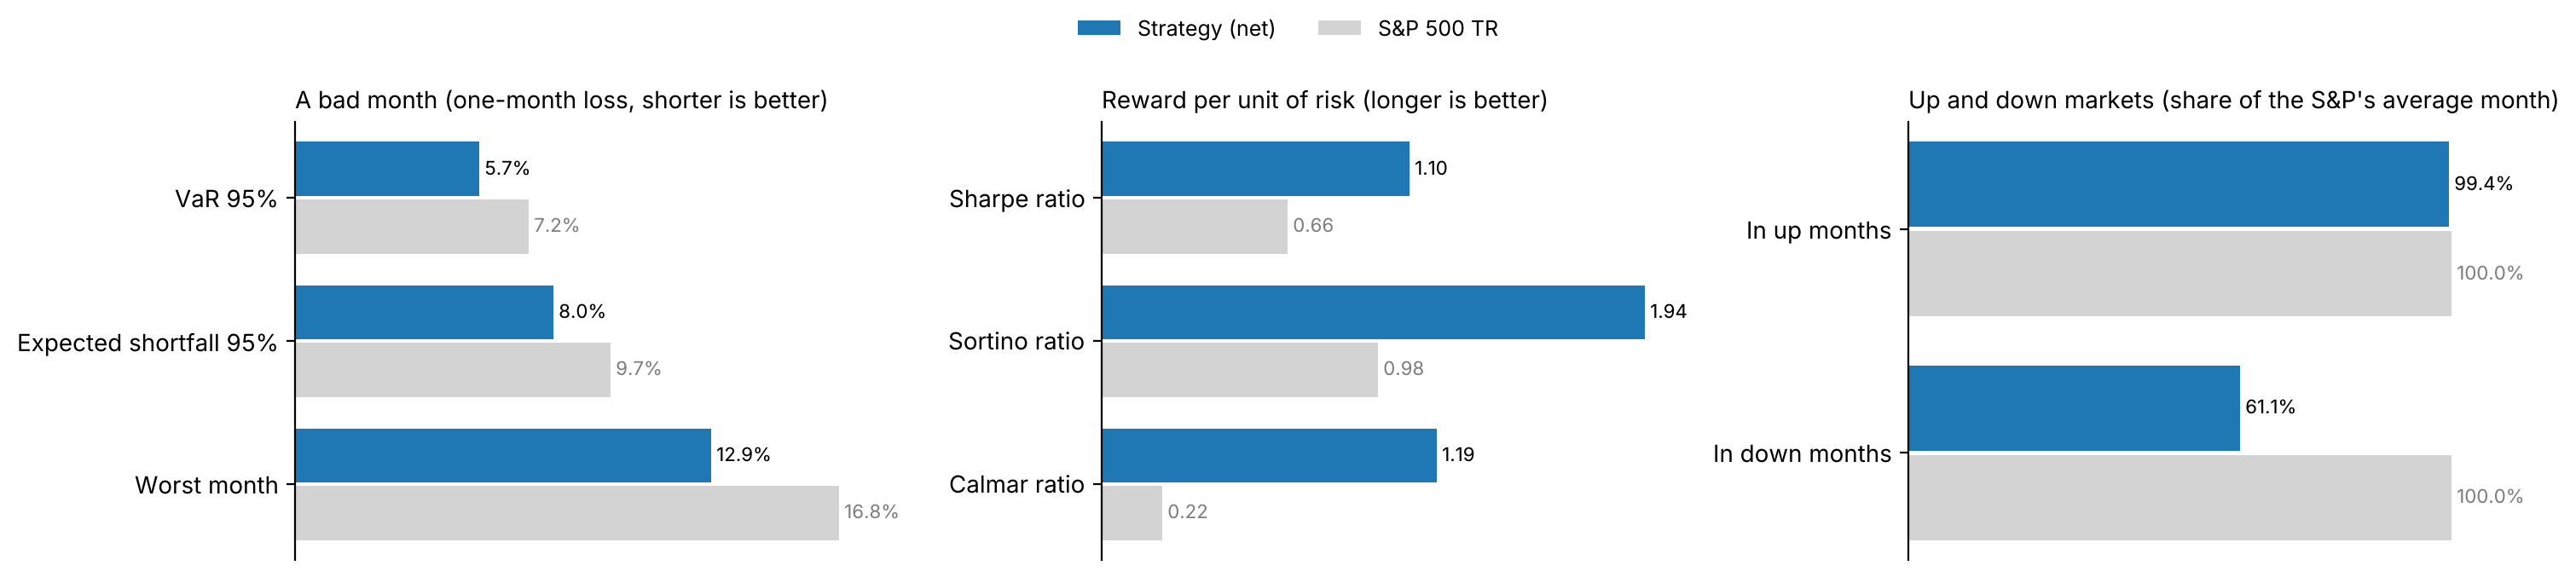

In [16]:
# The risk profile as paired bars (same view as the app): portfolio vs S&P 500 TR
groups = {
    'A bad month (one-month loss, shorter is better)': {
        'VaR 95%': risk.loc['VaR 95%, historical'], 'Expected shortfall 95%': risk.loc['CVaR 95% (expected shortfall)'],
        'Worst month': -risk.loc['Worst month']},
    'Reward per unit of risk (longer is better)': {
        'Sharpe ratio': pd.Series({'Strategy (net)': table.loc['Sharpe ratio', 'Strategy (net)'],
                                   'S&P 500 TR': table.loc['Sharpe ratio', 'S&P 500 TR']}),
        'Sortino ratio': risk.loc['Sortino ratio'], 'Calmar ratio': risk.loc['Calmar ratio']},
    "Up and down markets (share of the S&P's average month)": {
        'In up months': risk.loc['Upside capture'], 'In down months': risk.loc['Downside capture']},
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (title, rows) in zip(axes, groups.items()):
    y = np.arange(len(rows))[::-1]
    p = [v['Strategy (net)'] for v in rows.values()]; s = [v['S&P 500 TR'] for v in rows.values()]
    ax.barh(y + .2, p, .38, label='Strategy (net)'); ax.barh(y - .2, s, .38, label='S&P 500 TR', color='lightgrey')
    pct = 'Sharpe' not in title and 'Reward' not in title
    for yy, v in zip(y, p): ax.text(v, yy + .2, f' {v:.1%}' if pct else f' {v:.2f}', va='center', fontsize=8)
    for yy, v in zip(y, s): ax.text(v, yy - .2, f' {v:.1%}' if pct else f' {v:.2f}', va='center', fontsize=8, color='grey')
    ax.set_yticks(y, list(rows)); ax.set_title(title, fontsize=10, loc='left'); ax.set_xticks([])
    for side in ('top', 'right', 'bottom'): ax.spines[side].set_visible(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, .9)); plt.show()

in 1 month out of 20 the strategy lost more than 5.7% (s&p 7.2%); in those months the average loss was 8.0% (s&p 9.7%)


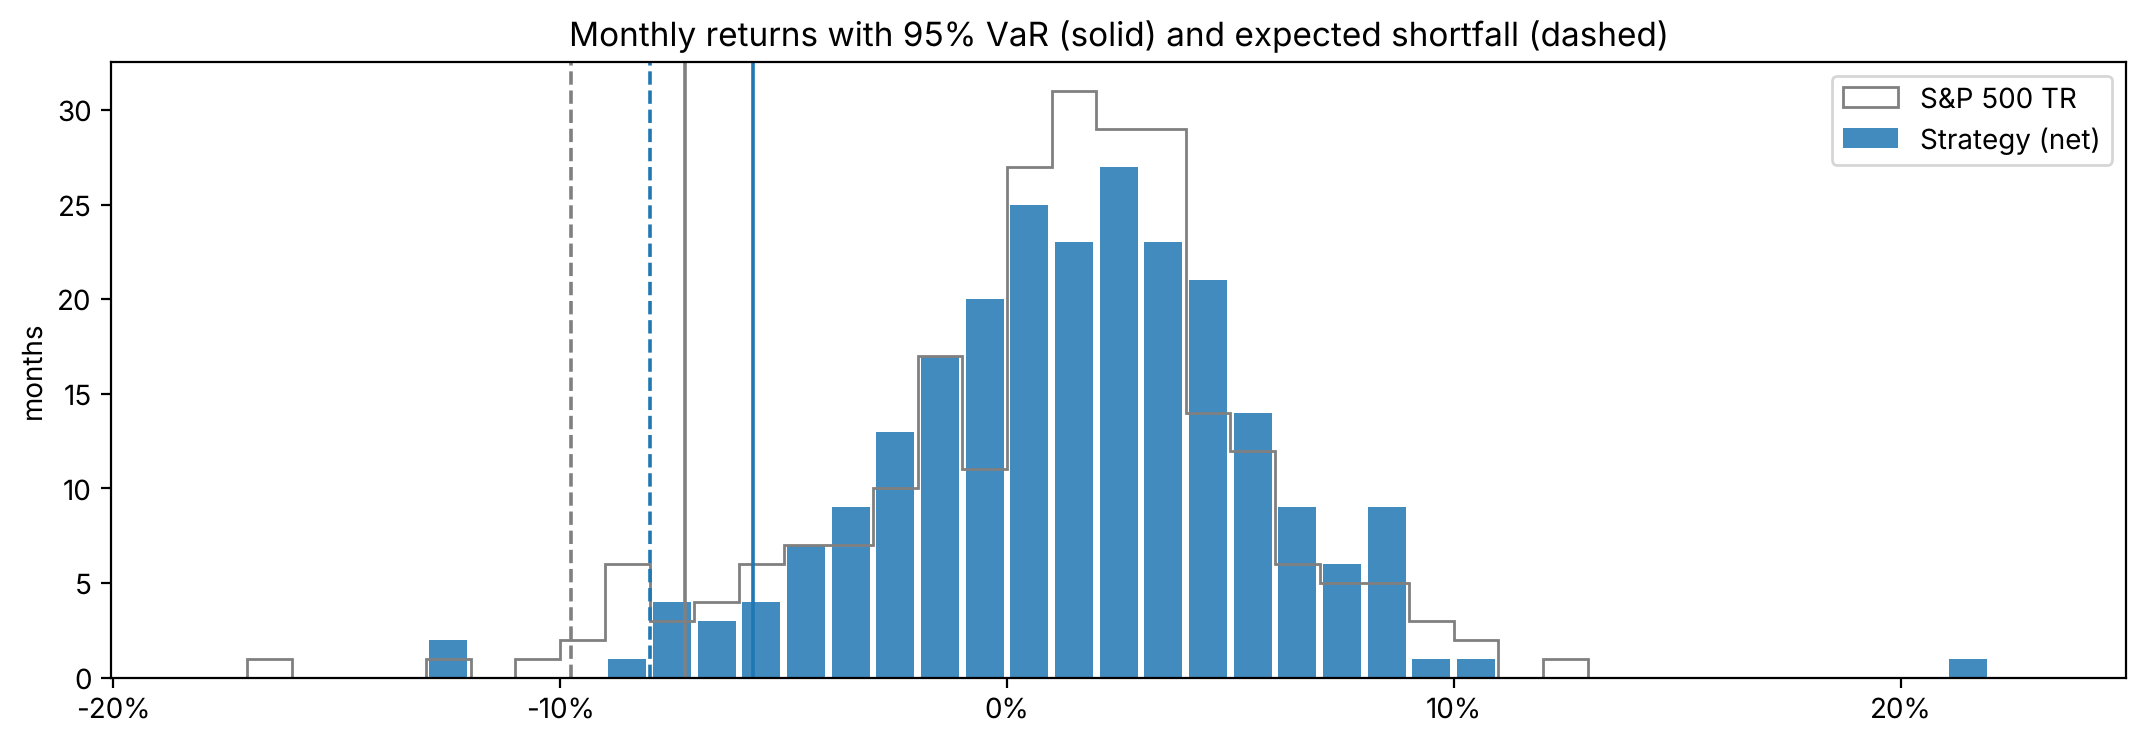

90.0%  95.0%  97.5%  99.0%  99.5%
Strategy (net) VaR, historical      0.035  0.057  0.073  0.086  0.116
               VaR, normal          0.039  0.054  0.067  0.082  0.092
               VaR, Cornish-Fisher  0.032  0.052  0.074  0.105  0.131
               Expected shortfall   0.062  0.080  0.096  0.114  0.126
S&P 500 TR     VaR, historical      0.050  0.072  0.087  0.101  0.120
               VaR, normal          0.046  0.062  0.076  0.092  0.103
               VaR, Cornish-Fisher  0.046  0.068  0.090  0.118  0.139
               Expected shortfall   0.079  0.097  0.112  0.133  0.146

In [17]:
# Value at risk at any confidence level (the app's slider): historical, normal, Cornish-Fisher, and expected shortfall
from scipy.stats import norm

def var_es(r_m, level):
    S, K, z = r_m.skew(), r_m.kurt(), norm.ppf(1 - level)
    z_cf = z + (z**2 - 1) * S / 6 + (z**3 - 3 * z) * K / 24 - (2 * z**3 - 5 * z) * S**2 / 36
    q = r_m.quantile(1 - level)
    return pd.Series({'VaR, historical': -q, 'VaR, normal': -(r_m.mean() + z * r_m.std()),
                      'VaR, Cornish-Fisher': -(r_m.mean() + z_cf * r_m.std()),
                      'Expected shortfall': -r_m[r_m <= q].mean()})

levels = [.90, .95, .975, .99, .995]
var_table = pd.concat({name: pd.DataFrame({f'{l:.1%}': var_es(r, l) for l in levels})
                       for name, r in {'Strategy (net)': strat_m, 'S&P 500 TR': bench_m}.items()})
v95, b95 = var_es(strat_m, .95), var_es(bench_m, .95)
print(f"in 1 month out of 20 the strategy lost more than {v95.iloc[0]:.1%} (s&p {b95.iloc[0]:.1%}); "
      f"in those months the average loss was {v95.iloc[3]:.1%} (s&p {b95.iloc[3]:.1%})")

fig, ax = plt.subplots(figsize=(13, 4))
bins = np.arange(np.floor(min(strat_m.min(), bench_m.min()) * 100) - 1, np.ceil(max(strat_m.max(), bench_m.max()) * 100) + 2) / 100
ax.hist(bench_m, bins=bins, histtype='step', color='grey', lw=1.2, label='S&P 500 TR')
ax.hist(strat_m, bins=bins, alpha=.85, rwidth=.85, label='Strategy (net)')
for v, c in ((v95, 'C0'), (b95, 'grey')):
    ax.axvline(-v.iloc[0], color=c, lw=1.3); ax.axvline(-v.iloc[3], color=c, lw=1.3, ls='--')
ax.set_title('Monthly returns with 95% VaR (solid) and expected shortfall (dashed)'); ax.set_ylabel('months')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}')); ax.legend(); plt.show()
var_table.round(3)

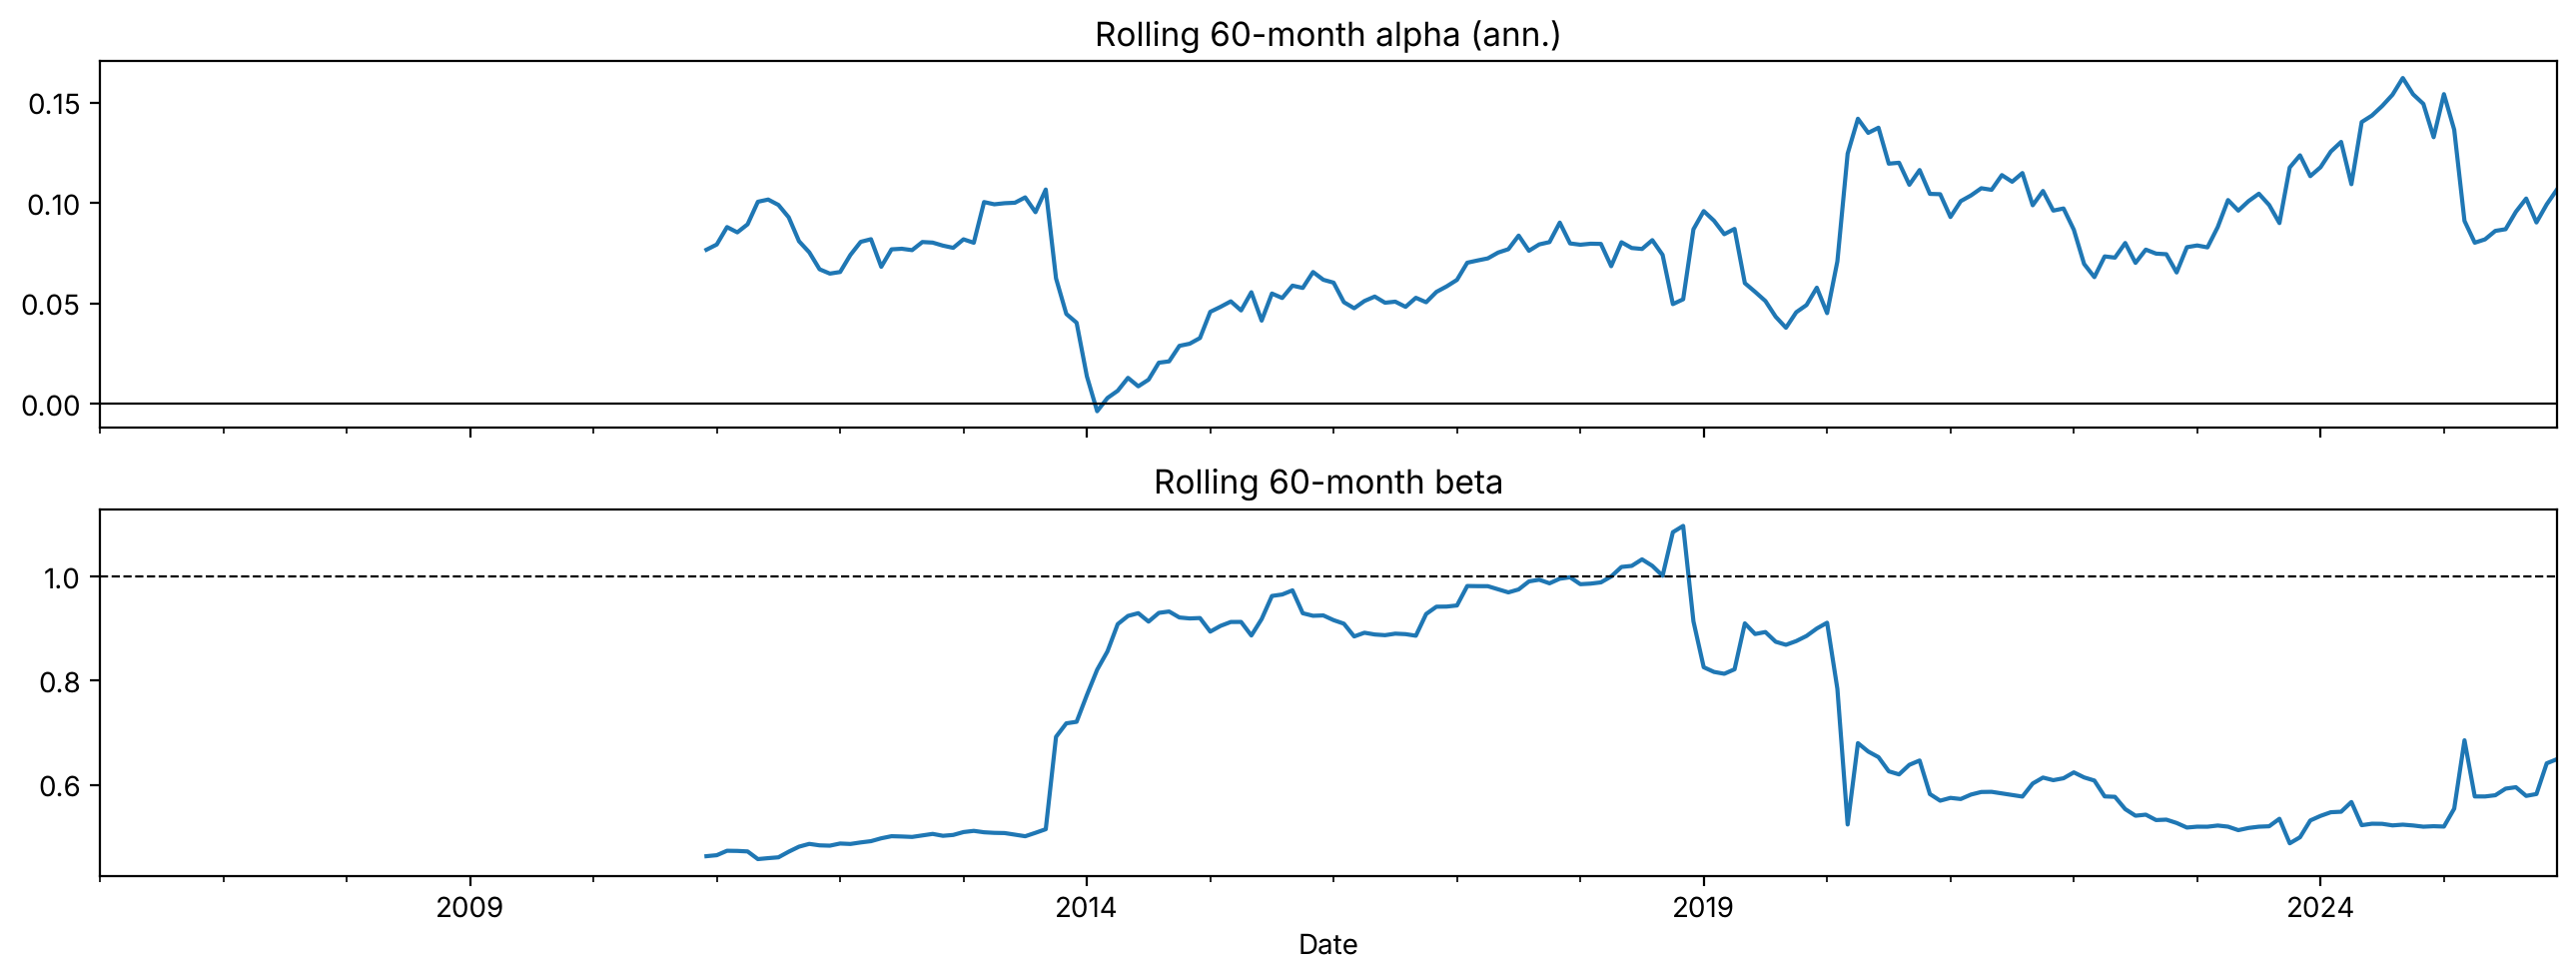

rolling alpha: min -0.4%, median 8.0%, positive in 99% of windows | rolling beta: 0.46 to 1.10


In [18]:
# Rolling 60-month alpha and beta (Lecture 3, quantstats rolling_greeks): is the edge stable or one lucky period?
ex_m, bex_m = strat_m - rf_m, bench_m - rf_m
roll_beta = ex_m.rolling(60).cov(bex_m) / bex_m.rolling(60).var()
roll_alpha = (ex_m.rolling(60).mean() - roll_beta * bex_m.rolling(60).mean()) * 12
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
roll_alpha.plot(ax=ax[0], title='Rolling 60-month alpha (ann.)'); ax[0].axhline(0, c='k', lw=.8)
roll_beta.plot(ax=ax[1], title='Rolling 60-month beta'); ax[1].axhline(1, c='k', lw=.8, ls='--')
plt.tight_layout(); plt.show()
print(f'rolling alpha: min {roll_alpha.min():.1%}, median {roll_alpha.median():.1%}, positive in '
      f'{(roll_alpha.dropna() > 0).mean():.0%} of windows | rolling beta: {roll_beta.min():.2f} to {roll_beta.max():.2f}')

### implementation

In [19]:
years = len(bt) / 252
gross_pair = tgt_pair.abs().sum(axis=1)
impl = pd.Series({
    'Turnover per year (x equity)': bt.turnover.sum() / years,
    'Annual cost drag (gross - net)': (bt.gross - bt.net).sum() / years,
    'Avg SPY exposure': bt.w_spy.mean(),
    'Avg gross exposure': bt.gross_exposure.mean(),
    'Max gross exposure': bt.gross_exposure.max(),
    'Pair trades opened': int(((gross_pair > 0) & (gross_pair.shift() == 0)).loc[START:END].sum()),
})
print(impl.round(3).to_string())

be = {c: stats(monthly(backtest(px, cost=c / 1e4).net))['Sharpe ratio'] for c in [0, 5, 10, 20, 30, 50]}
print('\nSharpe ratio by cost per unit traded (bp):', {k: round(float(v), 2) for k, v in be.items()})

from scipy.optimize import brentq
sharpe_sp = table.loc['Sharpe ratio', 'S&P 500 TR']
at_cost = lambda c, k: stats(monthly(backtest(px, cost=c).net))[k]
be_alpha = brentq(lambda c: at_cost(c, 'Alpha (ann.)'), 0, .05, xtol=1e-6)
be_sharpe = brentq(lambda c: at_cost(c, 'Sharpe ratio') - sharpe_sp, 0, .05, xtol=1e-6)
print(f'breakeven cost per unit traded (we assume {COST * 1e4:.0f} bp): alpha = 0 at {be_alpha * 1e4:.0f} bp, '
      f'sharpe = s&p 500 at {be_sharpe * 1e4:.0f} bp')

Turnover per year (x equity)       25.768
Annual cost drag (gross - net)      0.026
Avg SPY exposure                    0.995
Avg gross exposure                  1.854
Max gross exposure                  4.317
Pair trades opened                107.000



Sharpe ratio by cost per unit traded (bp): {0: 1.27, 5: 1.19, 10: 1.1, 20: 0.92, 30: 0.74, 50: 0.37}


breakeven cost per unit traded (we assume 10 bp): alpha = 0 at 46 bp, sharpe = s&p 500 at 34 bp


### robustness

In [20]:
rob = pd.DataFrame({
    'Base case':                 stats(strat_m),
    'Execution lag 2 days':      stats(monthly(backtest(px, lag=2).net)),
    f'In-sample ..{IS_END[:4]}': stats(strat_m.loc[:IS_END]),
    f'Out-of-sample {int(IS_END[:4]) + 1}..': stats(strat_m.loc[IS_END:].iloc[1:]),
}).loc[['Ann. avg return', 'Ann. volatility', 'Sharpe ratio', 'Alpha (ann.)', 'Beta', 'Information ratio']]
rob.round(4)

,Base case,Execution lag 2 days,In-sample ..2015,Out-of-sample 2016..
Ann. avg return,0.1736,0.1574,0.1421,0.2050
Ann. volatility,0.1434,0.1410,0.1304,0.1554
Sharpe ratio,1.0973,1.0024,1.0038,1.1819
Alpha (ann.),0.0966,0.0827,0.0881,0.1051
Beta,0.6074,0.5839,0.6047,0.6082
Information ratio,0.8757,0.7532,0.9412,0.8402


In [21]:
grid = pd.DataFrame({w: {zi: stats(monthly(backtest(px, use_spy=False, pair_kw=dict(win=w, z_in=zi)).net))['Sharpe ratio']
                         for zi in [1.5, 2.0, 2.5]} for w in [40, 60, 90, 120]}).T
grid.index.name, grid.columns.name = 'window (days)', 'entry z'
print('Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):')
grid.round(2)

Pair sleeve alone, net Sharpe ratio across signal parameters (base case: 60 days, z = 2.0):


entry z,1.5,2.0,2.5
window (days),,,
40,0.08,0.41,0.04
60,0.47,0.64,0.58
90,0.66,0.67,0.77
120,0.65,0.64,0.69


#### rule versions (ablation)
v1: 15% target on the equity sleeve only, dollar-neutral legs. final: one shared 15% budget and beta-neutral legs. motivated by consistency, compared once.

In [22]:
abl = pd.DataFrame({name: stats(monthly(backtest(px, vol_budget=vb, pair_kw=dict(beta_neutral=bn)).net))
                    for name, vb, bn in [('v1: sleeve target, dollar-neutral', False, False), ('+ shared vol budget', True, False),
                                         ('+ beta-neutral legs', False, True), ('final: both', True, True)]})
abl.loc[['Ann. avg return', 'Ann. volatility', 'Sharpe ratio', 'Alpha (ann.)', 'Beta', 'Max drawdown (monthly)']].round(4)

,"v1: sleeve target, dollar-neutral",+ shared vol budget,+ beta-neutral legs,final: both
Ann. avg return,0.1746,0.1679,0.1864,0.1736
Ann. volatility,0.1566,0.1403,0.1610,0.1434
Sharpe ratio,1.0115,1.0818,1.0566,1.0973
Alpha (ann.),0.0739,0.0826,0.0880,0.0966
Beta,0.8435,0.6905,0.8209,0.6074
Max drawdown (monthly),-0.2678,-0.1775,-0.2636,-0.1476


#### pair selection bias
xlu/xlp looked good in exploration, the low-beta rule came after. tested against 3y/5y betas, a one-off 1999–2005 pick, fixed xlu/xlp, and all 36 fixed pairs.

In [23]:
def pair_sharpes(**kw):
    p = backtest(px, use_spy=False, pair_kw=kw).net
    c = backtest(px, pair_kw=kw).net
    return pd.Series({'Pair sleeve Sharpe': stats(monthly(p))['Sharpe ratio'],
                      'Combined Sharpe': stats(monthly(c))['Sharpe ratio']})

static_pair = tuple(sorted(sector_betas(px, '1999', '2005').nsmallest(2).index))
rules = {
    'Base: lowest-beta pair, 1y betas':   {},
    'Lowest-beta pair, 3y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 3)),
    'Lowest-beta pair, 5y betas':         dict(pick=lambda px, y: lowbeta_pick(px, y, 5)),
    f'Static: 1999-2005 betas ({"/".join(static_pair)})': dict(pick=lambda px, y: static_pair),
    'Fixed XLP/XLU (hindsight)':          dict(pick=lambda px, y: ('XLP', 'XLU')),
}
pd.DataFrame({k: pair_sharpes(**v) for k, v in rules.items()}).T.round(2)

,Pair sleeve Sharpe,Combined Sharpe
"Base: lowest-beta pair, 1y betas",0.64,1.10
"Lowest-beta pair, 3y betas",0.62,1.06
"Lowest-beta pair, 5y betas",0.59,1.02
Static: 1999-2005 betas (XLE/XLP),-0.13,0.27
Fixed XLP/XLU (hindsight),0.66,1.11


In [24]:
from itertools import combinations
all36 = pd.Series({f'{a}/{b}': stats(monthly(backtest(px, use_spy=False, pair_kw=dict(pick=lambda px, y, a=a, b=b: (a, b))).net))['Sharpe ratio']
                   for a, b in combinations(SECTORS, 2)}).sort_values(ascending=False)
print(f'All 36 fixed sector pairs, pair sleeve net Sharpe: mean {all36.mean():.2f}, median {all36.median():.2f}, '
      f'{(all36 > 0).sum()} of 36 positive; XLP/XLU ranks #{all36.index.get_loc("XLP/XLU") + 1}')
all36.round(2).to_frame('Sharpe').T

All 36 fixed sector pairs, pair sleeve net Sharpe: mean 0.01, median 0.02, 20 of 36 positive; XLP/XLU ranks #1


,XLP/XLU,XLU/XLV,XLK/XLU,XLB/XLP,XLB/XLI,XLB/XLU,XLB/XLK,XLF/XLI,XLB/XLY,XLK/XLP,...,XLE/XLK,XLE/XLI,XLE/XLV,XLF/XLP,XLE/XLF,XLP/XLY,XLE/XLU,XLE/XLY,XLI/XLY,XLI/XLV
Sharpe,0.66,0.46,0.36,0.28,0.24,0.23,0.18,0.11,0.11,0.11,...,-0.14,-0.15,-0.15,-0.16,-0.17,-0.23,-0.25,-0.35,-0.35,-0.44


In [25]:
yearly = pd.DataFrame({'Strategy': (1 + bt.net).groupby(bt.index.year).prod() - 1,
                       'SPY sleeve': (1 + spy_only.net).groupby(spy_only.index.year).prod() - 1,
                       'Pair sleeve': (1 + pair_only.net).groupby(pair_only.index.year).prod() - 1,
                       'S&P 500 TR': (1 + bench_d).groupby(bench_d.index.year).prod() - 1})
print('years strategy beat benchmark:', (yearly.Strategy > yearly['S&P 500 TR']).sum(), 'of', len(yearly))
out = (yearly * 100).round(1)
out['pair held'] = betas['pair held'].reindex(out.index)
out

years strategy beat benchmark: 16 of 20


,Strategy,SPY sleeve,Pair sleeve,S&P 500 TR,pair held
Date,,,,,
2006,18.9,24.6,0.3,15.8,XLP/XLV
2007,7.5,3.8,7.4,5.5,XLP/XLU
2008,-4.8,-22.5,9.6,-37.0,XLP/XLV
2009,20.4,19.1,1.7,26.5,XLP/XLV
2010,10.8,13.5,-0.6,15.1,XLP/XLV
2011,3.6,3.7,0.7,2.1,XLP/XLU
2012,17.5,22.1,-3.5,16.0,XLP/XLU
2013,36.5,41.6,0.6,32.4,XLP/XLU
2014,23.0,13.7,11.0,13.7,XLP/XLU


### monte carlo
- block bootstrap: chain random 12-month blocks of 2006–2025 history. strategy, s&p and t-bill come from the same months, so crises, volatility clustering and the link between them stay intact
- 10,000 paths of 10 years for the client outlook, 5,000 paths of 20 years for the uncertainty of the sharpe ratio
- caveat: the paths resample our own backtest, so they inherit its optimism (pair selection bias, no parameter uncertainty). read them as "if the next decade looks like the last two", not as a forecast

10 years, $1m invested: median $5.13m (s&p $2.91m), bad case (5th pct) $2.61m. strategy ends ahead of the s&p in 93% of paths


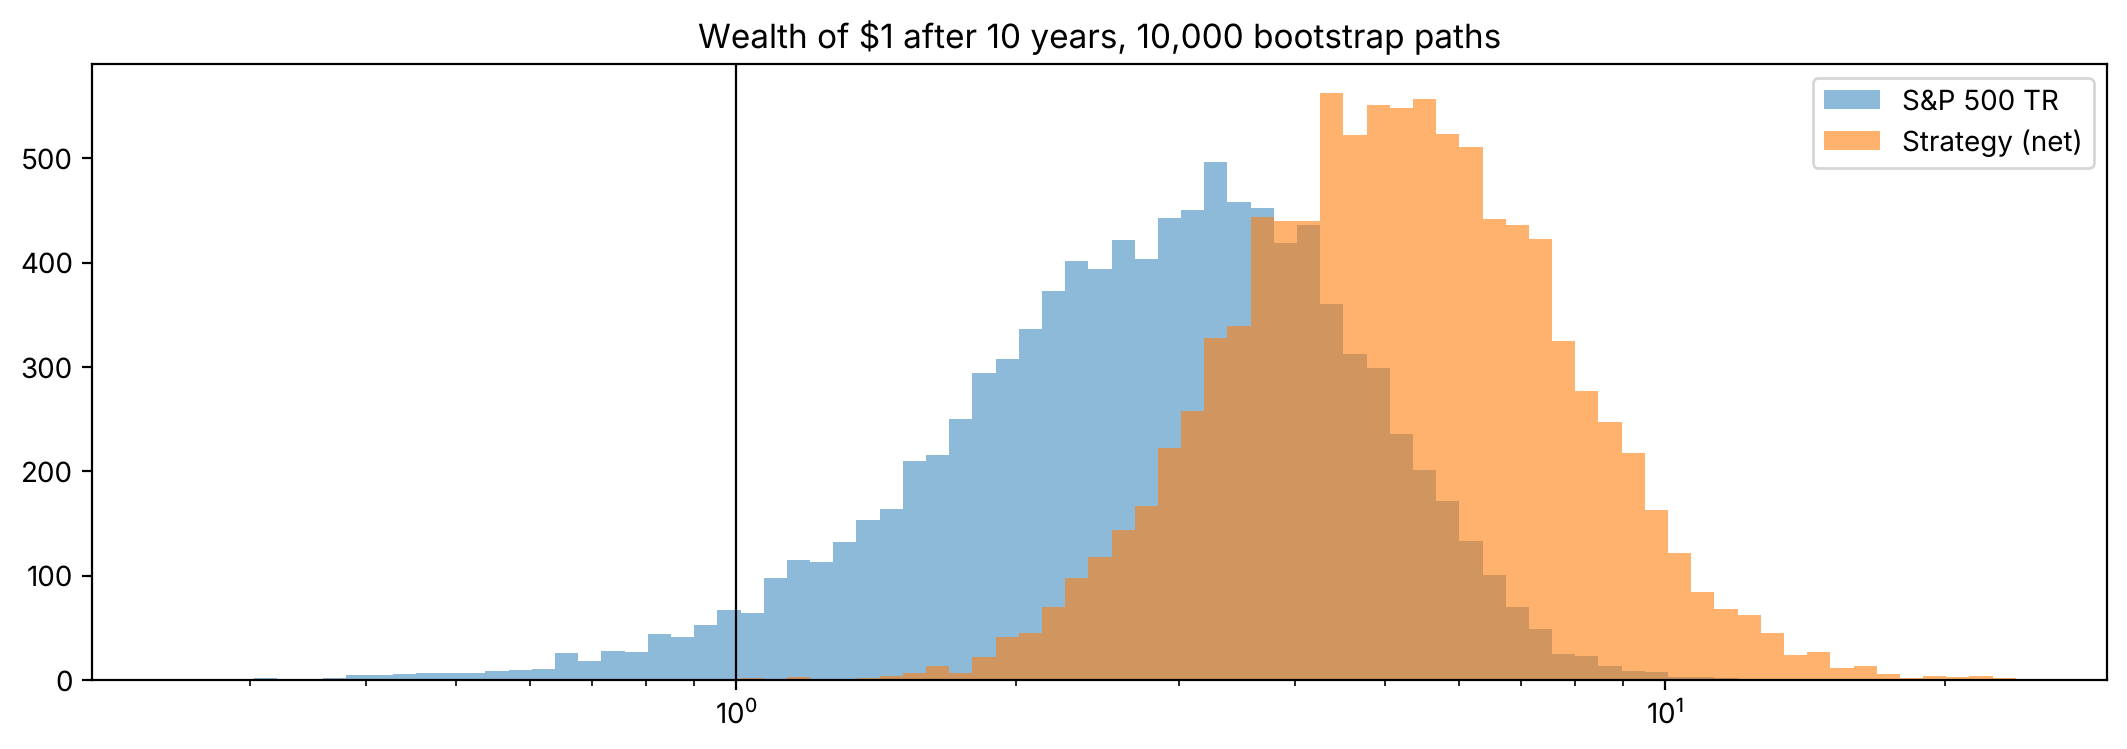

,Strategy (net),S&P 500 TR
Wealth of $1: 5th percentile,2.609,1.109
Wealth of $1: median,5.130,2.907
Wealth of $1: mean,5.586,3.121
Wealth of $1: 95th percentile,9.992,5.883
Probability of a loss,0.000,0.036
Max drawdown: median,-0.148,-0.270
Max drawdown: 5th percentile (bad case),-0.225,-0.555
Sharpe ratio: 5th percentile,0.647,0.064
Sharpe ratio: 95th percentile,1.580,1.311


In [26]:
def monte_carlo(r_m, months=120, paths=10_000, block=12, seed=42):
    X = np.column_stack([r_m, bench_m.loc[r_m.index], rf_m.loc[r_m.index]])
    starts = np.random.default_rng(seed).integers(0, len(X) - block + 1, size=(paths, months // block))
    sim = X[(starts[..., None] + np.arange(block)).reshape(paths, -1)]          # paths x months x (strategy, s&p, rf)
    W = np.cumprod(1 + sim[..., :2], axis=1)
    dd = (W / np.maximum.accumulate(W, axis=1) - 1).min(axis=1)
    ex = sim[..., :2] - sim[..., 2:]
    sharpe = ex.mean(axis=1) / ex.std(axis=1, ddof=1) * np.sqrt(12)
    end = W[:, -1]
    pct = lambda a, k: np.percentile(a, k, axis=0)
    table = pd.DataFrame({
        'Wealth of $1: 5th percentile': pct(end, 5), 'Wealth of $1: median': pct(end, 50),
        'Wealth of $1: mean': end.mean(axis=0), 'Wealth of $1: 95th percentile': pct(end, 95),
        'Probability of a loss': (end < 1).mean(axis=0),
        'Max drawdown: median': pct(dd, 50), 'Max drawdown: 5th percentile (bad case)': pct(dd, 5),
        'Sharpe ratio: 5th percentile': pct(sharpe, 5), 'Sharpe ratio: 95th percentile': pct(sharpe, 95),
    }, index=['Strategy (net)', 'S&P 500 TR']).T
    head = dict(beats_sp=(end[:, 0] > end[:, 1]).mean(), sharpe_above=(sharpe[:, 0] > sharpe[:, 1]).mean())
    return table, head, W

mc, mc_head, mc_W = monte_carlo(strat_m)
mc_end = mc_W[:, -1]
print(f"10 years, $1m invested: median ${mc.loc['Wealth of $1: median', 'Strategy (net)']:.2f}m "
      f"(s&p ${mc.loc['Wealth of $1: median', 'S&P 500 TR']:.2f}m), bad case (5th pct) ${mc.loc['Wealth of $1: 5th percentile', 'Strategy (net)']:.2f}m. "
      f"strategy ends ahead of the s&p in {mc_head['beats_sp']:.0%} of paths")
fig, ax = plt.subplots(figsize=(13, 4))
bins = np.logspace(np.log10(mc_end.min()), np.log10(mc_end.max()), 80)
ax.hist(mc_end[:, 1], bins=bins, alpha=.5, label='S&P 500 TR'); ax.hist(mc_end[:, 0], bins=bins, alpha=.6, label='Strategy (net)')
ax.set_xscale('log'); ax.axvline(1, c='k', lw=.8); ax.set_title('Wealth of $1 after 10 years, 10,000 bootstrap paths'); ax.legend(); plt.show()
mc.round(3)

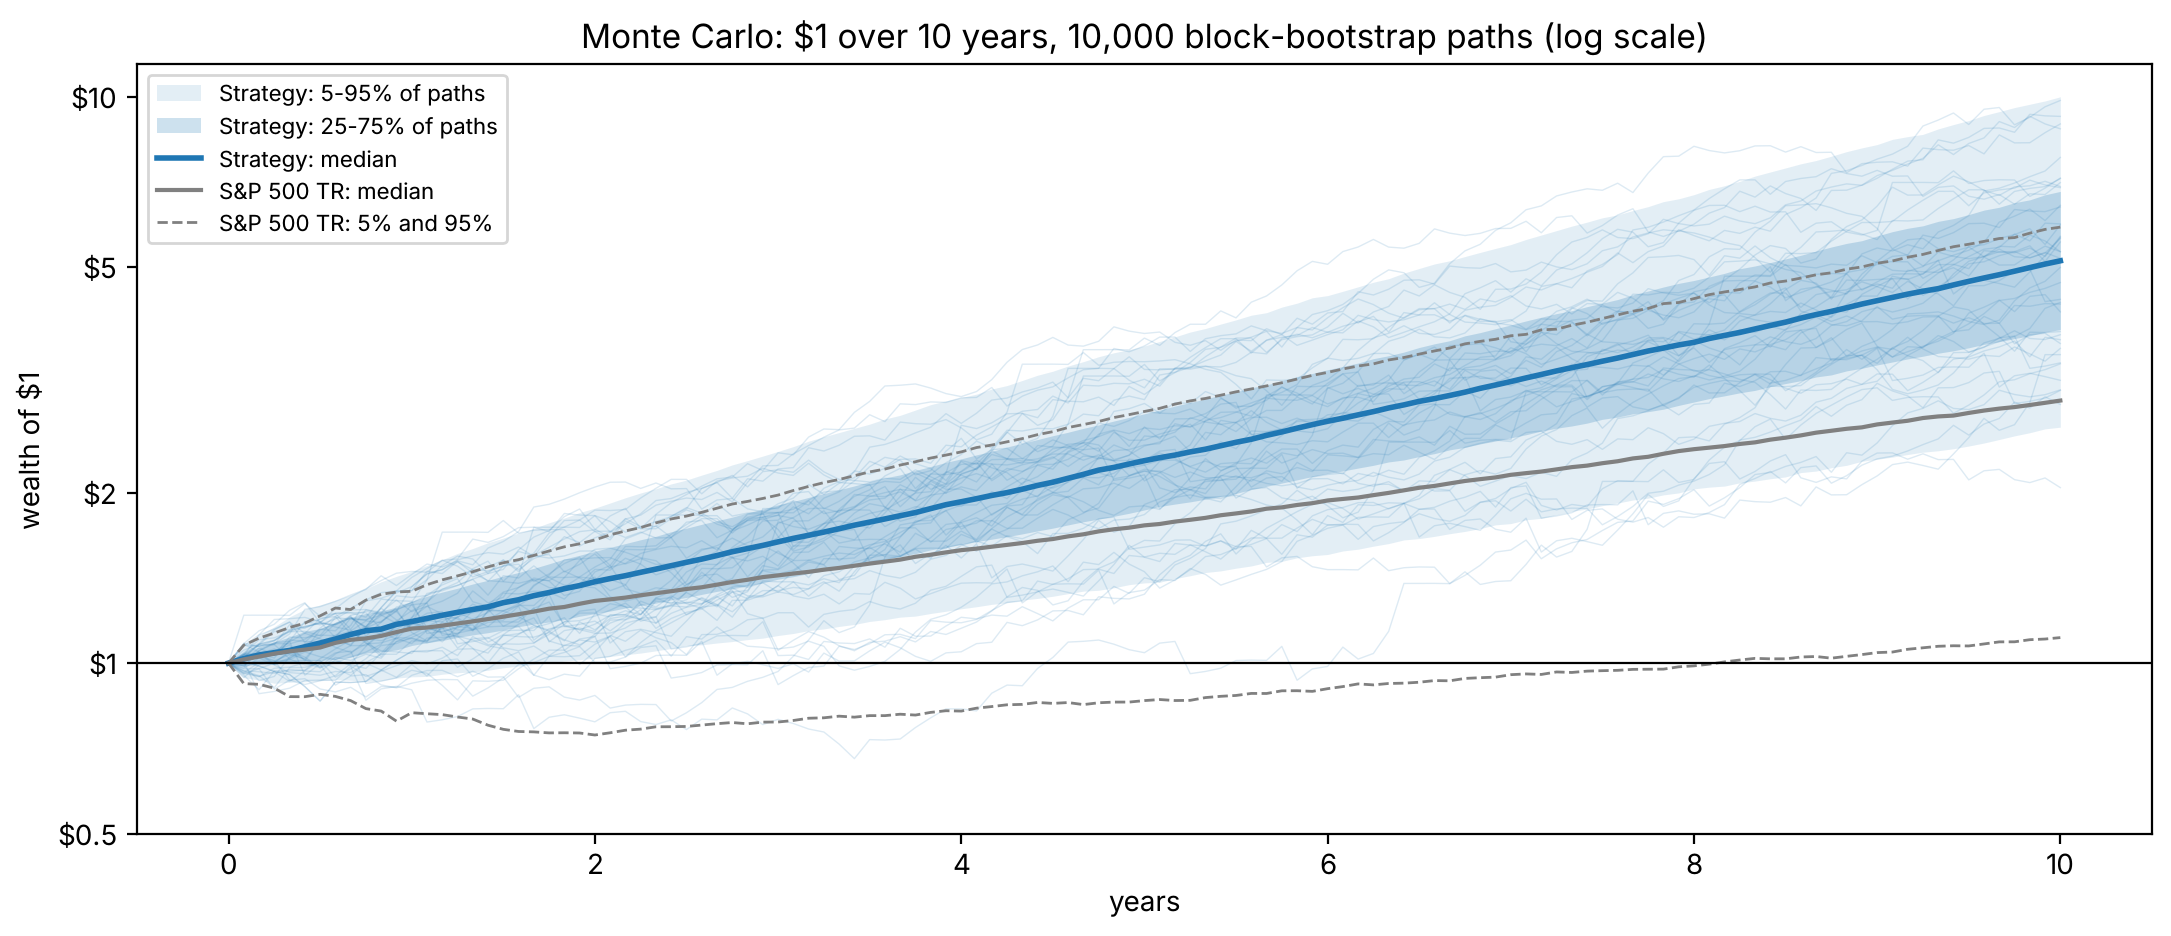

In [27]:
# Fan chart: how the 10,000 paths spread out over the 10 years (same view as the app)
q = np.concatenate([np.ones((5, 1, 2)), np.percentile(mc_W, [5, 25, 50, 75, 95], axis=0)], axis=1)   # all start at $1
t = np.arange(q.shape[1]) / 12
fig, ax = plt.subplots(figsize=(13, 5))
for path in mc_W[:40, :, 0]:
    ax.plot(t, np.r_[1, path], color='C0', lw=.5, alpha=.15)
ax.fill_between(t, q[0, :, 0], q[4, :, 0], color='C0', alpha=.12, lw=0, label='Strategy: 5-95% of paths')
ax.fill_between(t, q[1, :, 0], q[3, :, 0], color='C0', alpha=.22, lw=0, label='Strategy: 25-75% of paths')
ax.plot(t, q[2, :, 0], color='C0', lw=2, label='Strategy: median')
ax.plot(t, q[2, :, 1], color='grey', lw=1.5, label='S&P 500 TR: median')
ax.plot(t, q[0, :, 1], color='grey', lw=1, ls='--', label='S&P 500 TR: 5% and 95%'); ax.plot(t, q[4, :, 1], color='grey', lw=1, ls='--')
ax.set_yscale('log'); ax.set_yticks([.5, 1, 2, 5, 10], ['$0.5', '$1', '$2', '$5', '$10']); ax.minorticks_off(); ax.axhline(1, c='k', lw=.8); ax.set_xlabel('years'); ax.set_ylabel('wealth of $1')
ax.set_title('Monte Carlo: $1 over 10 years, 10,000 block-bootstrap paths (log scale)'); ax.legend(loc='upper left', fontsize=8); plt.show()

In [28]:
mc20, mc20_head, _ = monte_carlo(strat_m, months=240, paths=5_000, seed=7)
print(f"20-year sharpe ratio, 90% range: strategy {mc20.loc['Sharpe ratio: 5th percentile', 'Strategy (net)']:.2f} to "
      f"{mc20.loc['Sharpe ratio: 95th percentile', 'Strategy (net)']:.2f}, s&p {mc20.loc['Sharpe ratio: 5th percentile', 'S&P 500 TR']:.2f} to "
      f"{mc20.loc['Sharpe ratio: 95th percentile', 'S&P 500 TR']:.2f}. strategy sharpe above the s&p's in {mc20_head['sharpe_above']:.0%} of paths")

20-year sharpe ratio, 90% range: strategy 0.78 to 1.44, s&p 0.23 to 1.13. strategy sharpe above the s&p's in 97% of paths


### risks
- selection bias: rule came after seeing xlu/xlp. holds for 1/3/5y betas, fails for a one-off 1999–2005 pick and for the average fixed pair → read pair alpha as optimistic. params are defaults, not tuned
- survivorship: none, all etfs live since 1998
- leverage: gross can exceed 4x (2x spy + 2x gross legs), needs margin. financing at fixed spreads
- rule versions: v1 targeted 15% on the equity sleeve only and used dollar-neutral legs. the shared budget and beta-neutral legs were added for consistency (stated 15% target, zero beta per trade) and compared to v1 once (ablation table). a whole-book scaling variant was also tried once and rejected (lower sharpe, 6.8x gross)
- realised daily vol still runs above 15% in sudden spikes: the budget is reset monthly
- concentration: one equity index, two defensive sectors
- regime: monthly vol reset lags fast crashes. pair can decouple
- data: `^IRX` is a discount yield, approximates t-bill return. yahoo not point-in-time
- fat tails: excess kurtosis above 2 (s&p ~1.2). at 99% the cornish-fisher var is above the normal var, so a normal model understates rare losses
- the monte carlo resamples our own history: it shows the spread of outcomes if the future looks like 2006–2025, not a forecast

### ai disclosure
claude code used for strategy screening (`sandbox/`) and writing/debugging this notebook. checked via look-ahead test, spy vs `^SP500TR`, gross vs net + cost breakeven, selection-bias checks, fresh colab rerun. instructor approval: _todo_